# Import Libraries & load data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.signal import find_peaks, savgol_filter
from scipy.stats import linregress

# Cargar datos
keysight_data = np.loadtxt('250mK_DEV13_275_16_dmm_keysight_signal.dat')  # Datos del Keysight
lockin_data = np.loadtxt('250mK_DEV13_275_16_mf1_X.dat')    # Datos del Lock-in

# Definir parámetros
Rs = 5000  # Resistencia en serie en Ohms
Betha=1
dI = 5e-9 * Betha  # Excitación de corriente del Lock-in (1 nA)
G_0 = 7.74809173e-5  # Conductancia cuántica en Siemens

In [ ]:
plt.rcParams.update({
    "figure.figsize": (12, 8),     # tamaño figura global
    "figure.dpi": 300,
    "font.size": 14,               # tamaño de fuente general
    "axes.titlesize": 18,          # títulos de los ejes
    "axes.labelsize": 16,          # labels: xlabel, ylabel
    "xtick.labelsize": 14,         # números del eje X
    "ytick.labelsize": 14,         # números del eje Y
    "legend.fontsize": 14,         # leyendas
})

# Reshape & Rs correction

In [3]:
# Extraer columnas relevantes
temperature = keysight_data[:, 0]  # Temperature (1ª columna de ambos datasets)
I_bias = keysight_data[:, 1]  # Corriente aplicada (I_bias): 2ª columna de ambos datasets
V_drop = keysight_data[:, 3]  # Caída de voltaje medida (V_drop): 4ª columna del Keysight
dV = lockin_data[:, 3]  # Respuesta en voltaje del Lock-in (dV): 4ª columna del Lock-in

# Obtener valores únicos de temperatura y I_bias
T_values = np.unique(temperature)  # Valores únicos de temperatura
I_values = np.unique(I_bias)  # Valores únicos de I_bias

# Crear matrices vacías para almacenar los datos reorganizados
num_T = len(T_values)  # Número de valores de temperatura
num_I = len(I_values)  # Número de valores de I_bias

V_real_matrix = np.zeros((num_I, num_T))  # Matriz para V_real
dV_real_matrix = np.zeros((num_I, num_T))  # Matriz para dV_real
dIdV_matrix = np.zeros((num_I, num_T))  # Matriz para dI/dV
dVdI_matrix = np.zeros((num_I, num_T))  # Matriz para dI/dV

# Crear un índice para mapear T e I a índices de matriz
T_index = {T: i for i, T in enumerate(T_values)}
I_index = {I: j for j, I in enumerate(I_values)}

# Llenar las matrices con los datos reorganizados
for idx, (T, I, V, dV_val) in enumerate(zip(temperature, I_bias, V_drop, dV)):
    i = T_index[T]
    j = I_index[I]
    
    # Corregir el voltaje real y la respuesta del Lock-in
    V_real_matrix[j, i] = V - I * Rs
    dV_real_matrix[j, i] = dV_val - dI * Rs
    
    # Calcular la conductancia diferencial (dI/dV)
    if dV_real_matrix[j, i] != 0:  # Evitar división por cero
        dIdV_matrix[j, i] = (dI / dV_real_matrix[j, i]) / G_0
        dVdI_matrix[j, i] = (dV_real_matrix[j, i] / dI)

# Eliminar NaN values (reemplazar por 0)
dV_real_matrix[np.isnan(dV_real_matrix)] = 0
dIdV_matrix[np.isnan(dIdV_matrix)] = 0
dVdI_matrix[np.isnan(dVdI_matrix)] = 0
V_real_matrix[np.isnan(V_real_matrix)] = 0

In [4]:
I_values*1e9

array([-128.      , -127.783336, -127.566672, ...,  131.563696,
        131.78036 ,  131.997025])

In [5]:
dIdV_matrix

array([[  13.85012166,   48.58230653,   17.01266671, ...,  -55.90972681,
           9.93597397,   -7.73771344],
       [  13.85241062, -245.4422449 ,   20.54980771, ...,  -27.15580885,
           8.61501288,   -5.49442437],
       [  13.93075589, -722.44073492,   21.48888101, ...,  -54.1390711 ,
           8.47742695,   -6.75194717],
       ...,
       [  16.68346215,   16.65823851,   17.05495007, ...,   11.57848635,
          11.74867946,   11.58432399],
       [  16.58493545,   16.82641579,   17.10461568, ...,   11.61801156,
          11.75742212,   11.58012277],
       [  16.46430433,   16.95096189,   17.08401768, ...,   11.60896262,
          11.74090755,   11.57766063]])

In [6]:
dVdI_matrix

array([[  931.86212,   265.66058,   758.63496, ...,  -230.84362,
         1298.95708, -1667.98678],
       [  931.70814,   -52.58428,   628.05472, ...,  -475.2723 ,
         1498.12936, -2349.00016],
       [  926.4683 ,   -17.865  ,   600.60846, ...,  -238.39352,
         1522.44352, -1911.5084 ],
       ...,
       [  773.60464,   774.77602,   756.75412, ...,  1114.68834,
         1098.5408 ,  1114.12662],
       [  778.20042,   767.03226,   754.55678, ...,  1110.8961 ,
         1097.72394,  1114.53082],
       [  783.90216,   761.39654,   755.46654, ...,  1111.76202,
         1099.26798,  1114.76784]])

# 2D plot representation

### First, I_offset correction

In [7]:
I_offset = 0e-9  # Desplazamiento de corriente  en Amperios (A)
I_bias_withoffset = I_values  + I_offset # añadir el offset
I_bias_withoffset

array([-1.28000000e-07, -1.27783336e-07, -1.27566672e-07, ...,
        1.31563696e-07,  1.31780360e-07,  1.31997025e-07])

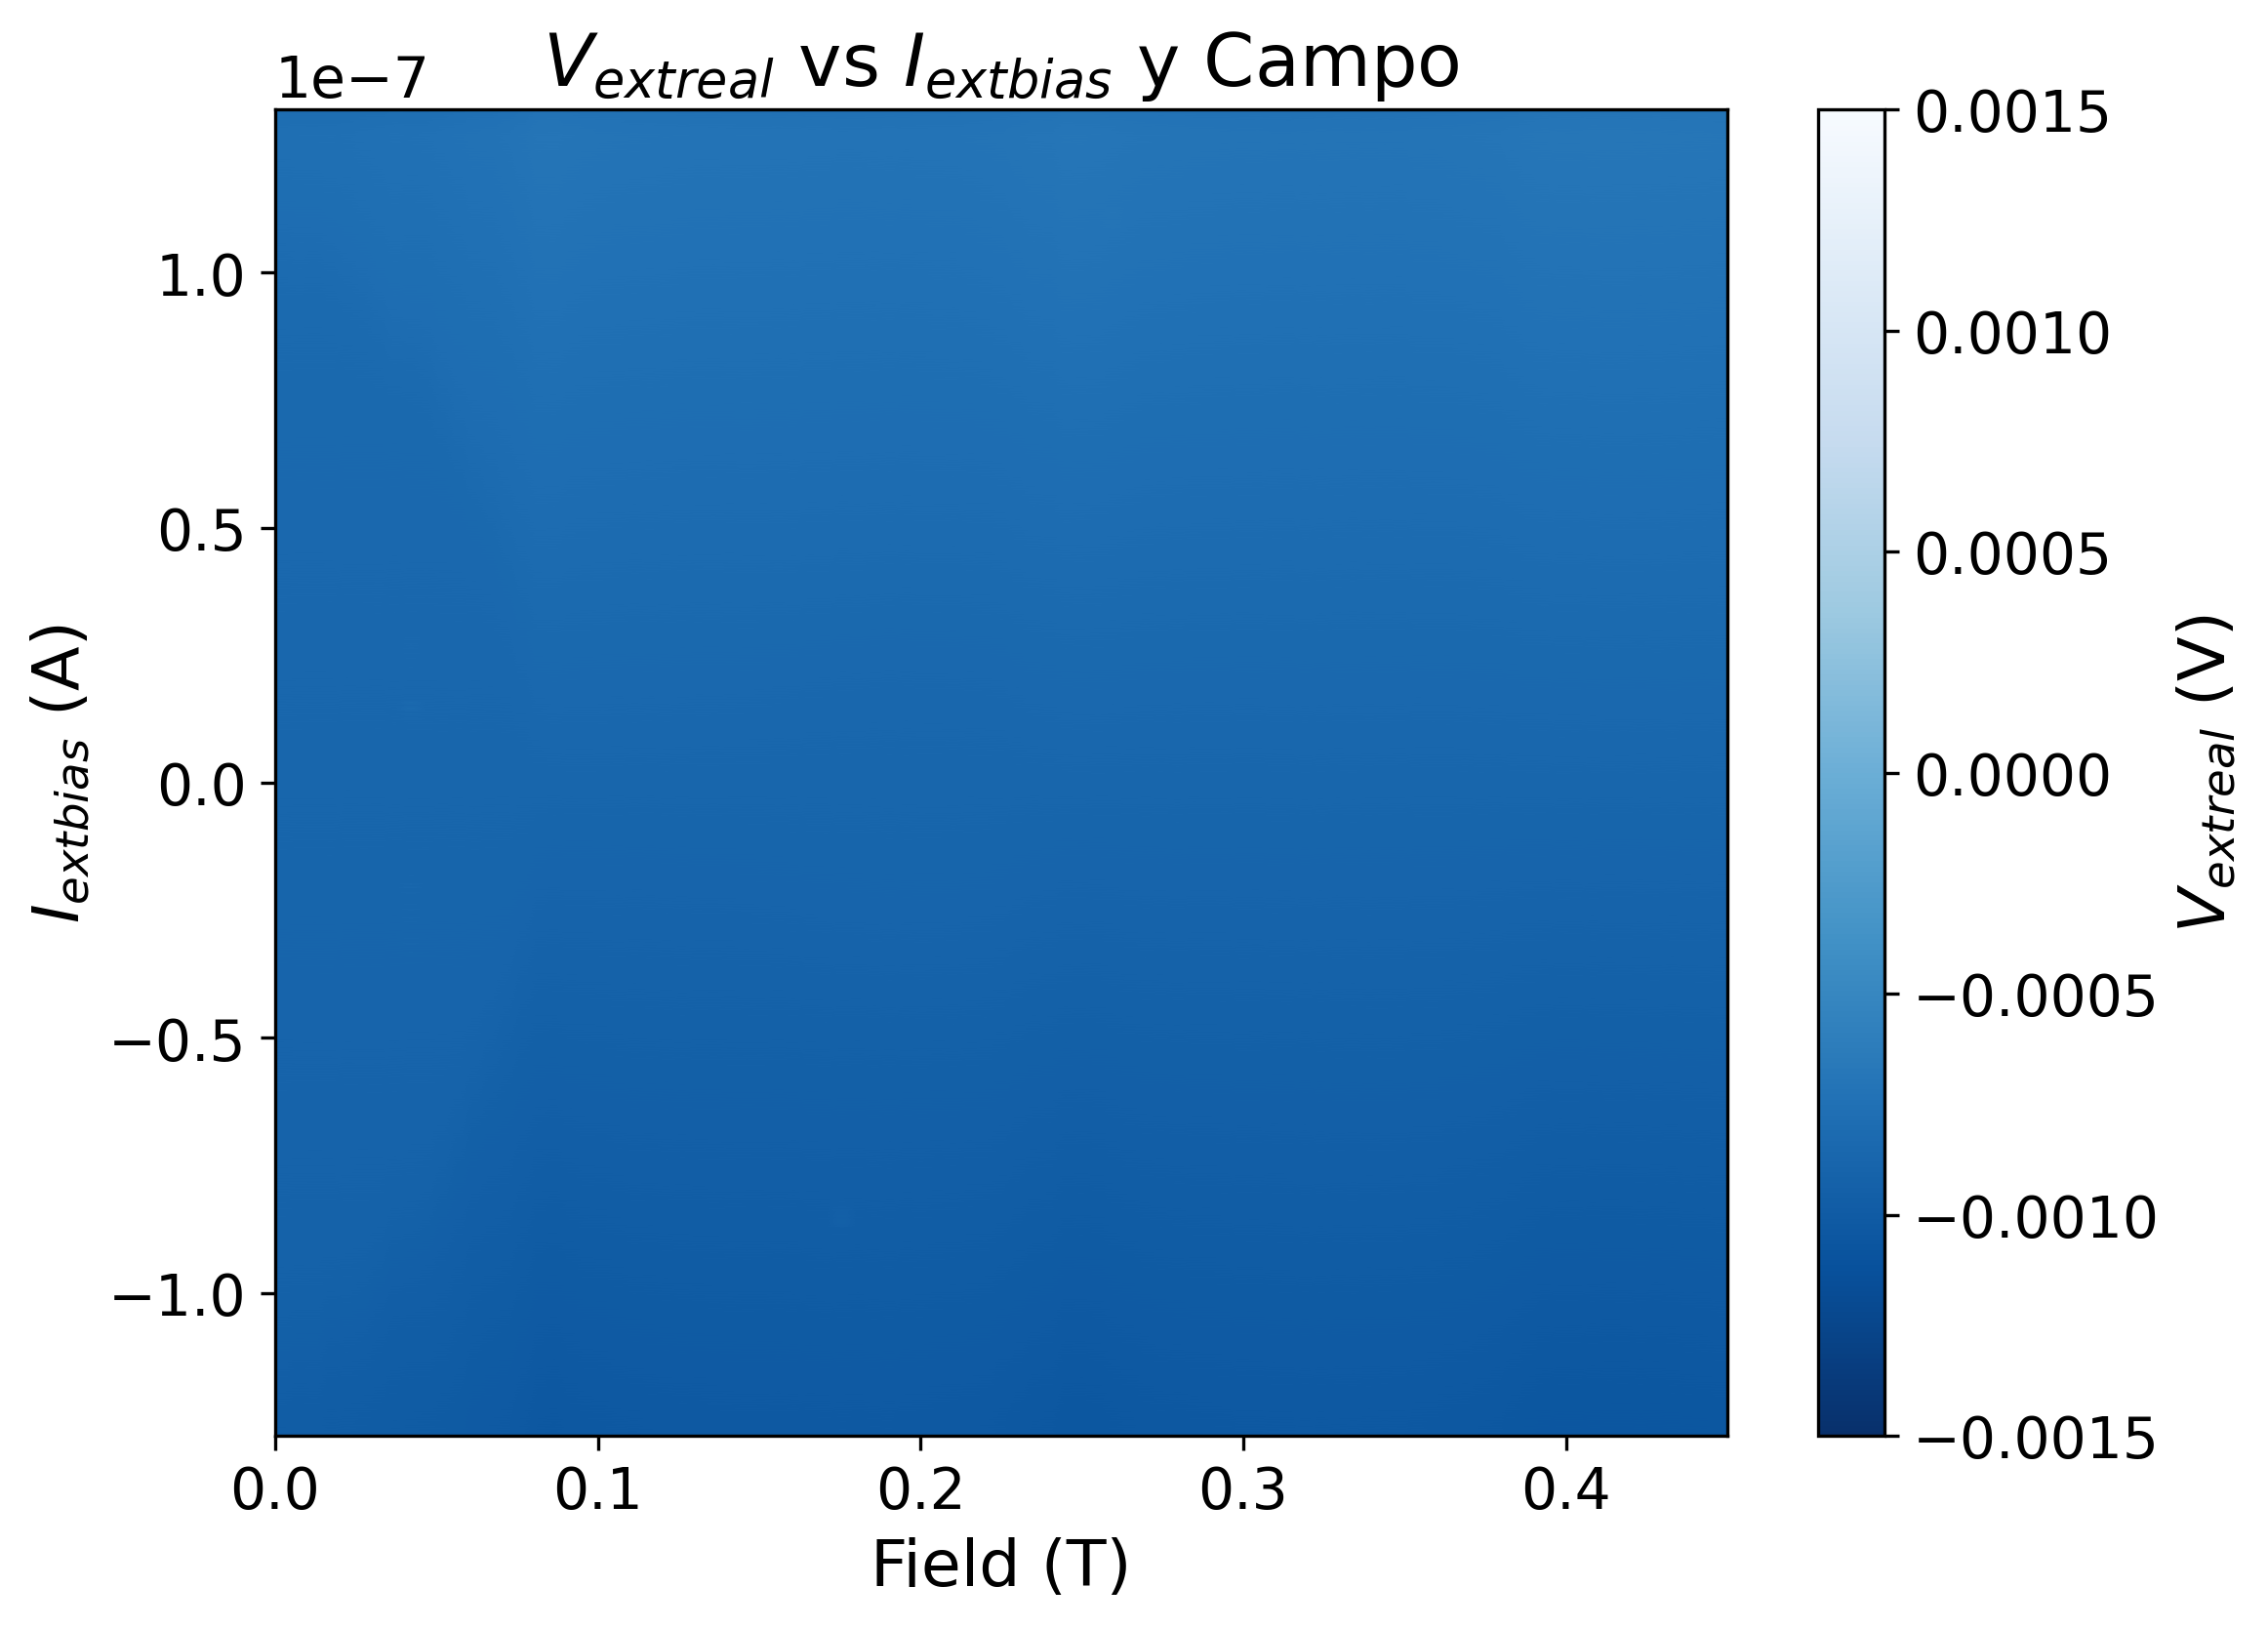

In [8]:
# Crear un mapa de color para V_real
plt.figure(figsize=(8, 6))
plt.imshow(V_real_matrix, aspect='auto', origin='lower', 
           extent=[T_values.min(), T_values.max(), I_bias_withoffset.min(), I_bias_withoffset.max()], 
           cmap='Blues_r', vmin=-1.5e-3, vmax=1.5e-3)  # Ajusta vmin y vmax según tus datos
plt.colorbar(label='$V_{\text{real}}$ (V)')
plt.xlabel('Field (T)')
plt.ylabel('$I_{\text{bias}}$ (A)')
plt.title('$V_{\text{real}}$ vs $I_{\text{bias}}$ y Campo')
plt.show()

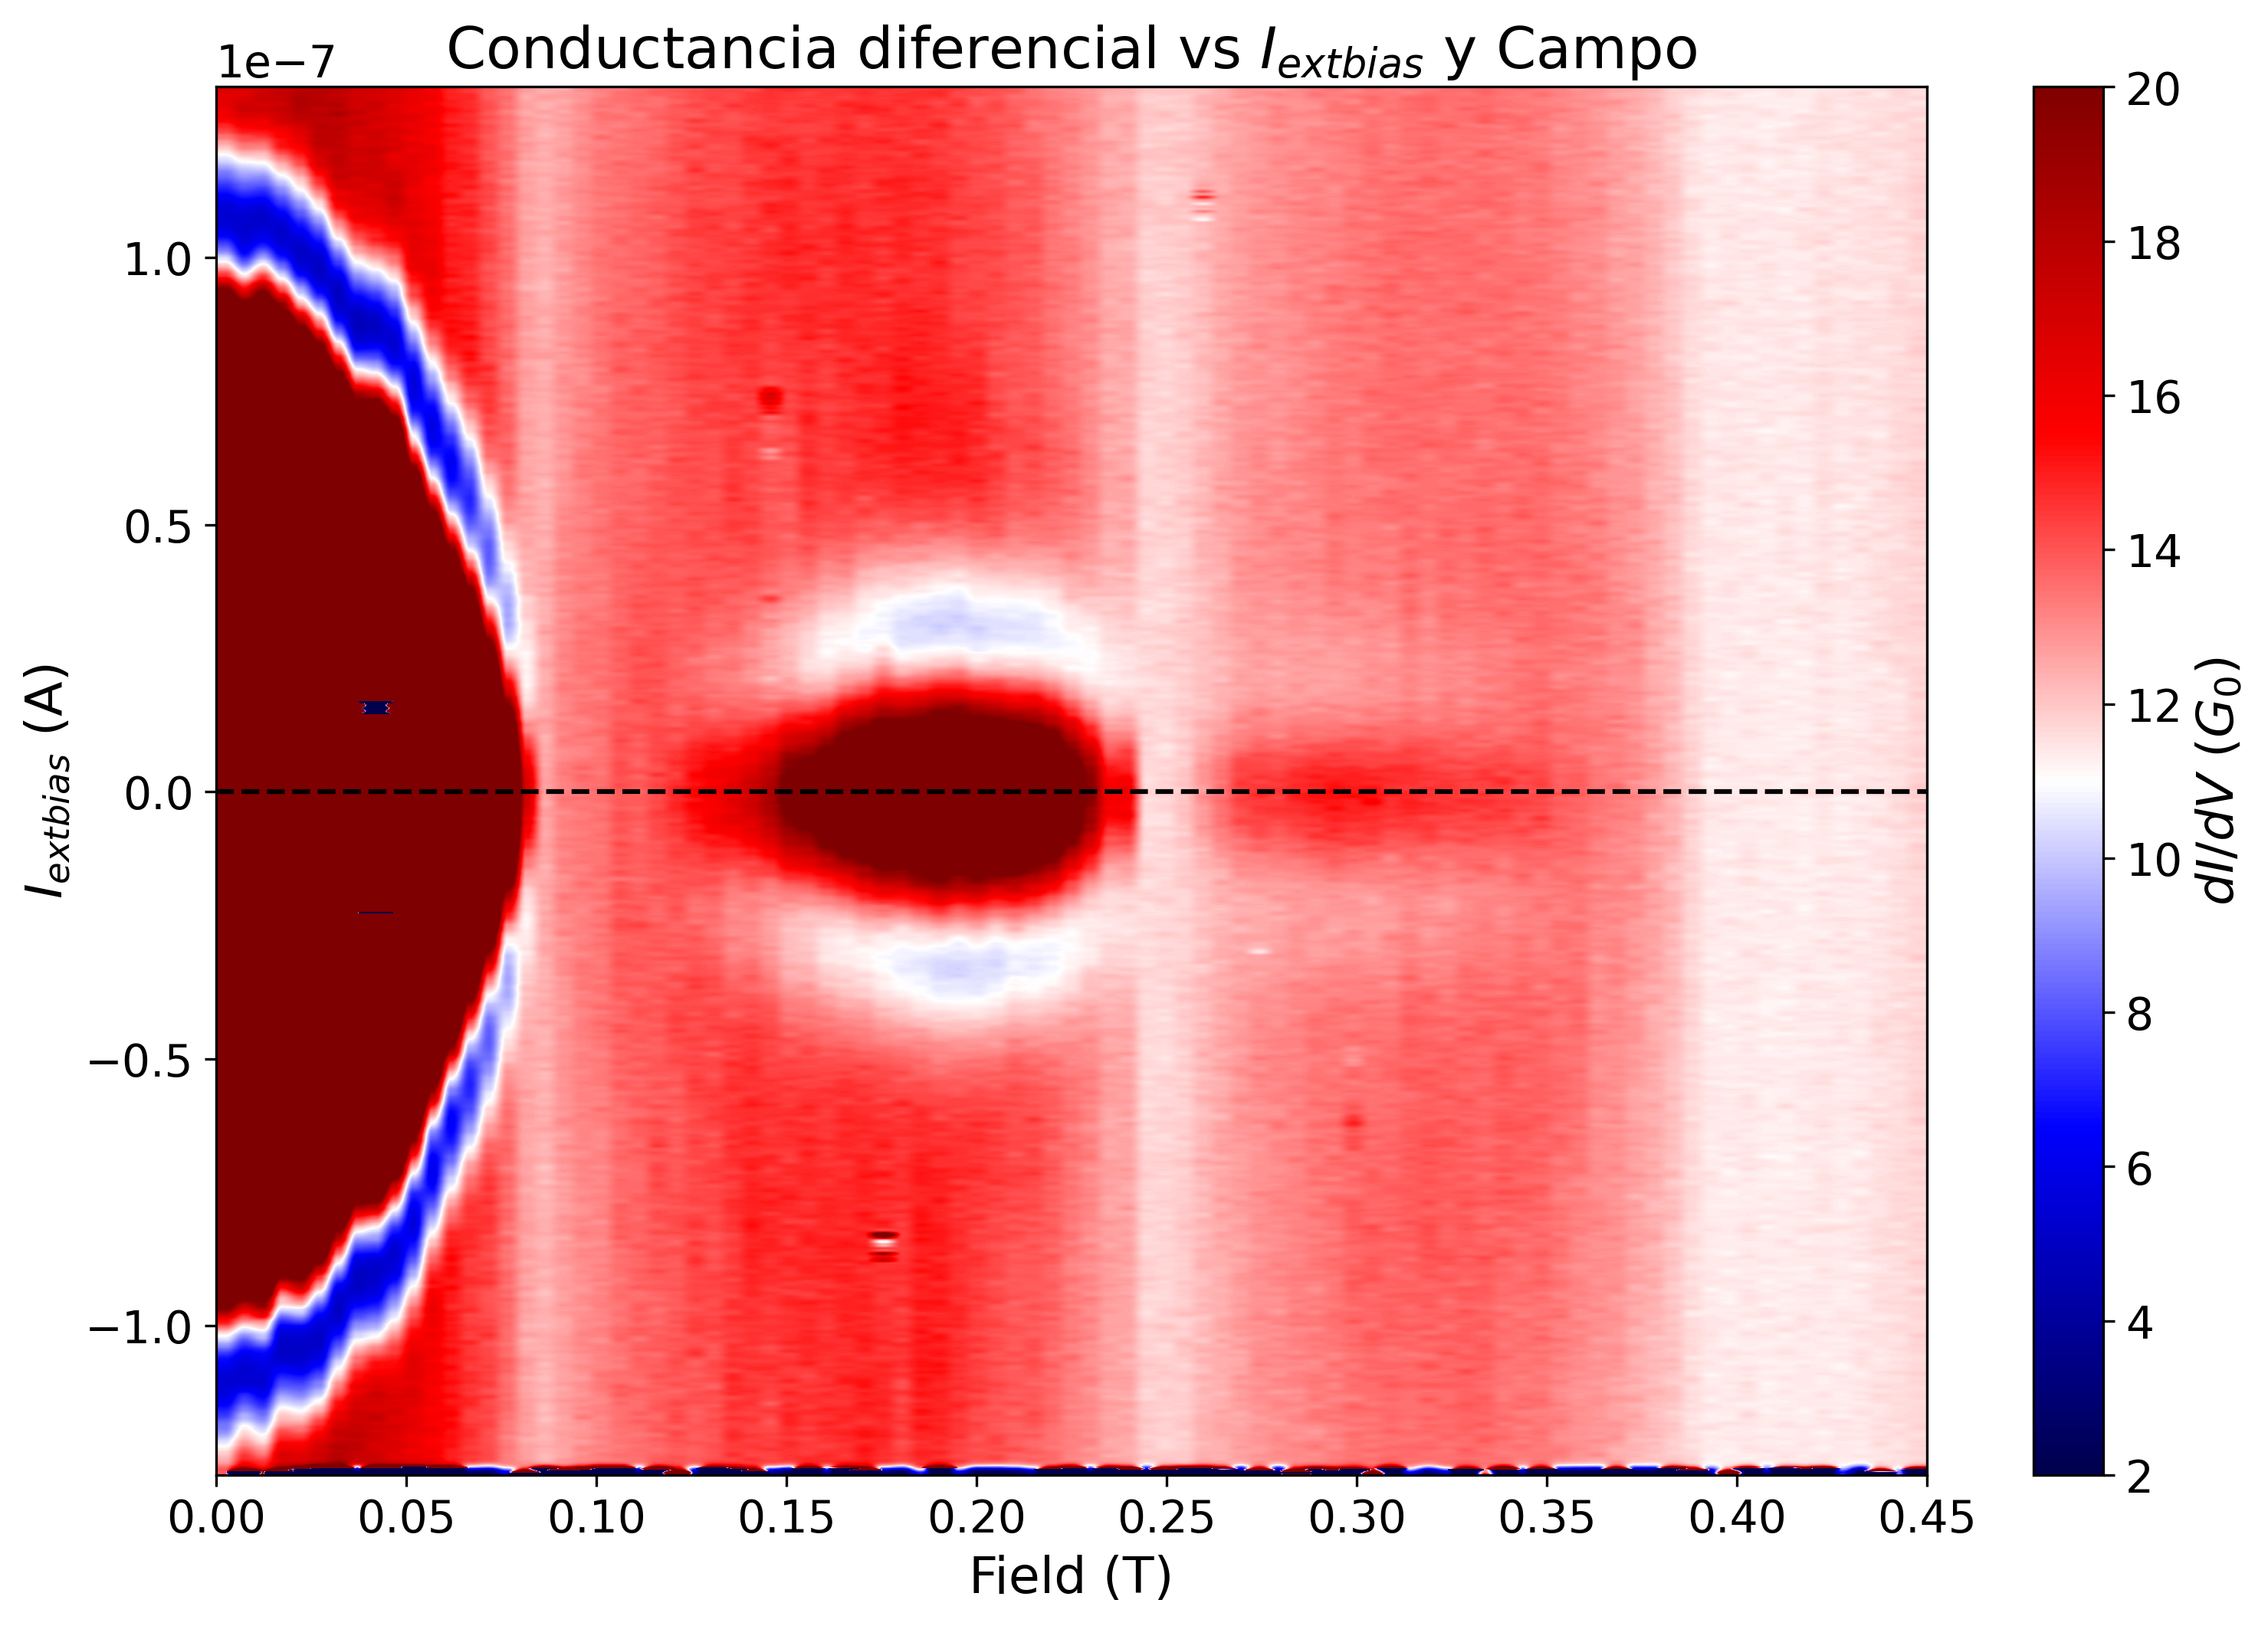

In [9]:
# Crear un mapa de color para dI/dV
plt.imshow(dIdV_matrix, aspect='auto', origin='lower', 
           extent=[T_values.min(), T_values.max(), I_bias_withoffset.min(), I_bias_withoffset.max()], 
           cmap='seismic', vmin=2, vmax=20)  # Ajusta vmin y vmax según tus datos
plt.colorbar(label='$dI/dV$ ($G_0$)')
plt.xlabel('Field (T)')
plt.ylabel('$I_{\text{bias}}$ (A)')
plt.axhline(0, color='black', linestyle='--')  # maya en y=0

plt.title('Conductancia diferencial vs $I_{\text{bias}}$ y Campo')
plt.show()

In [11]:
I_bias_withoffset.min()

-1.28e-07

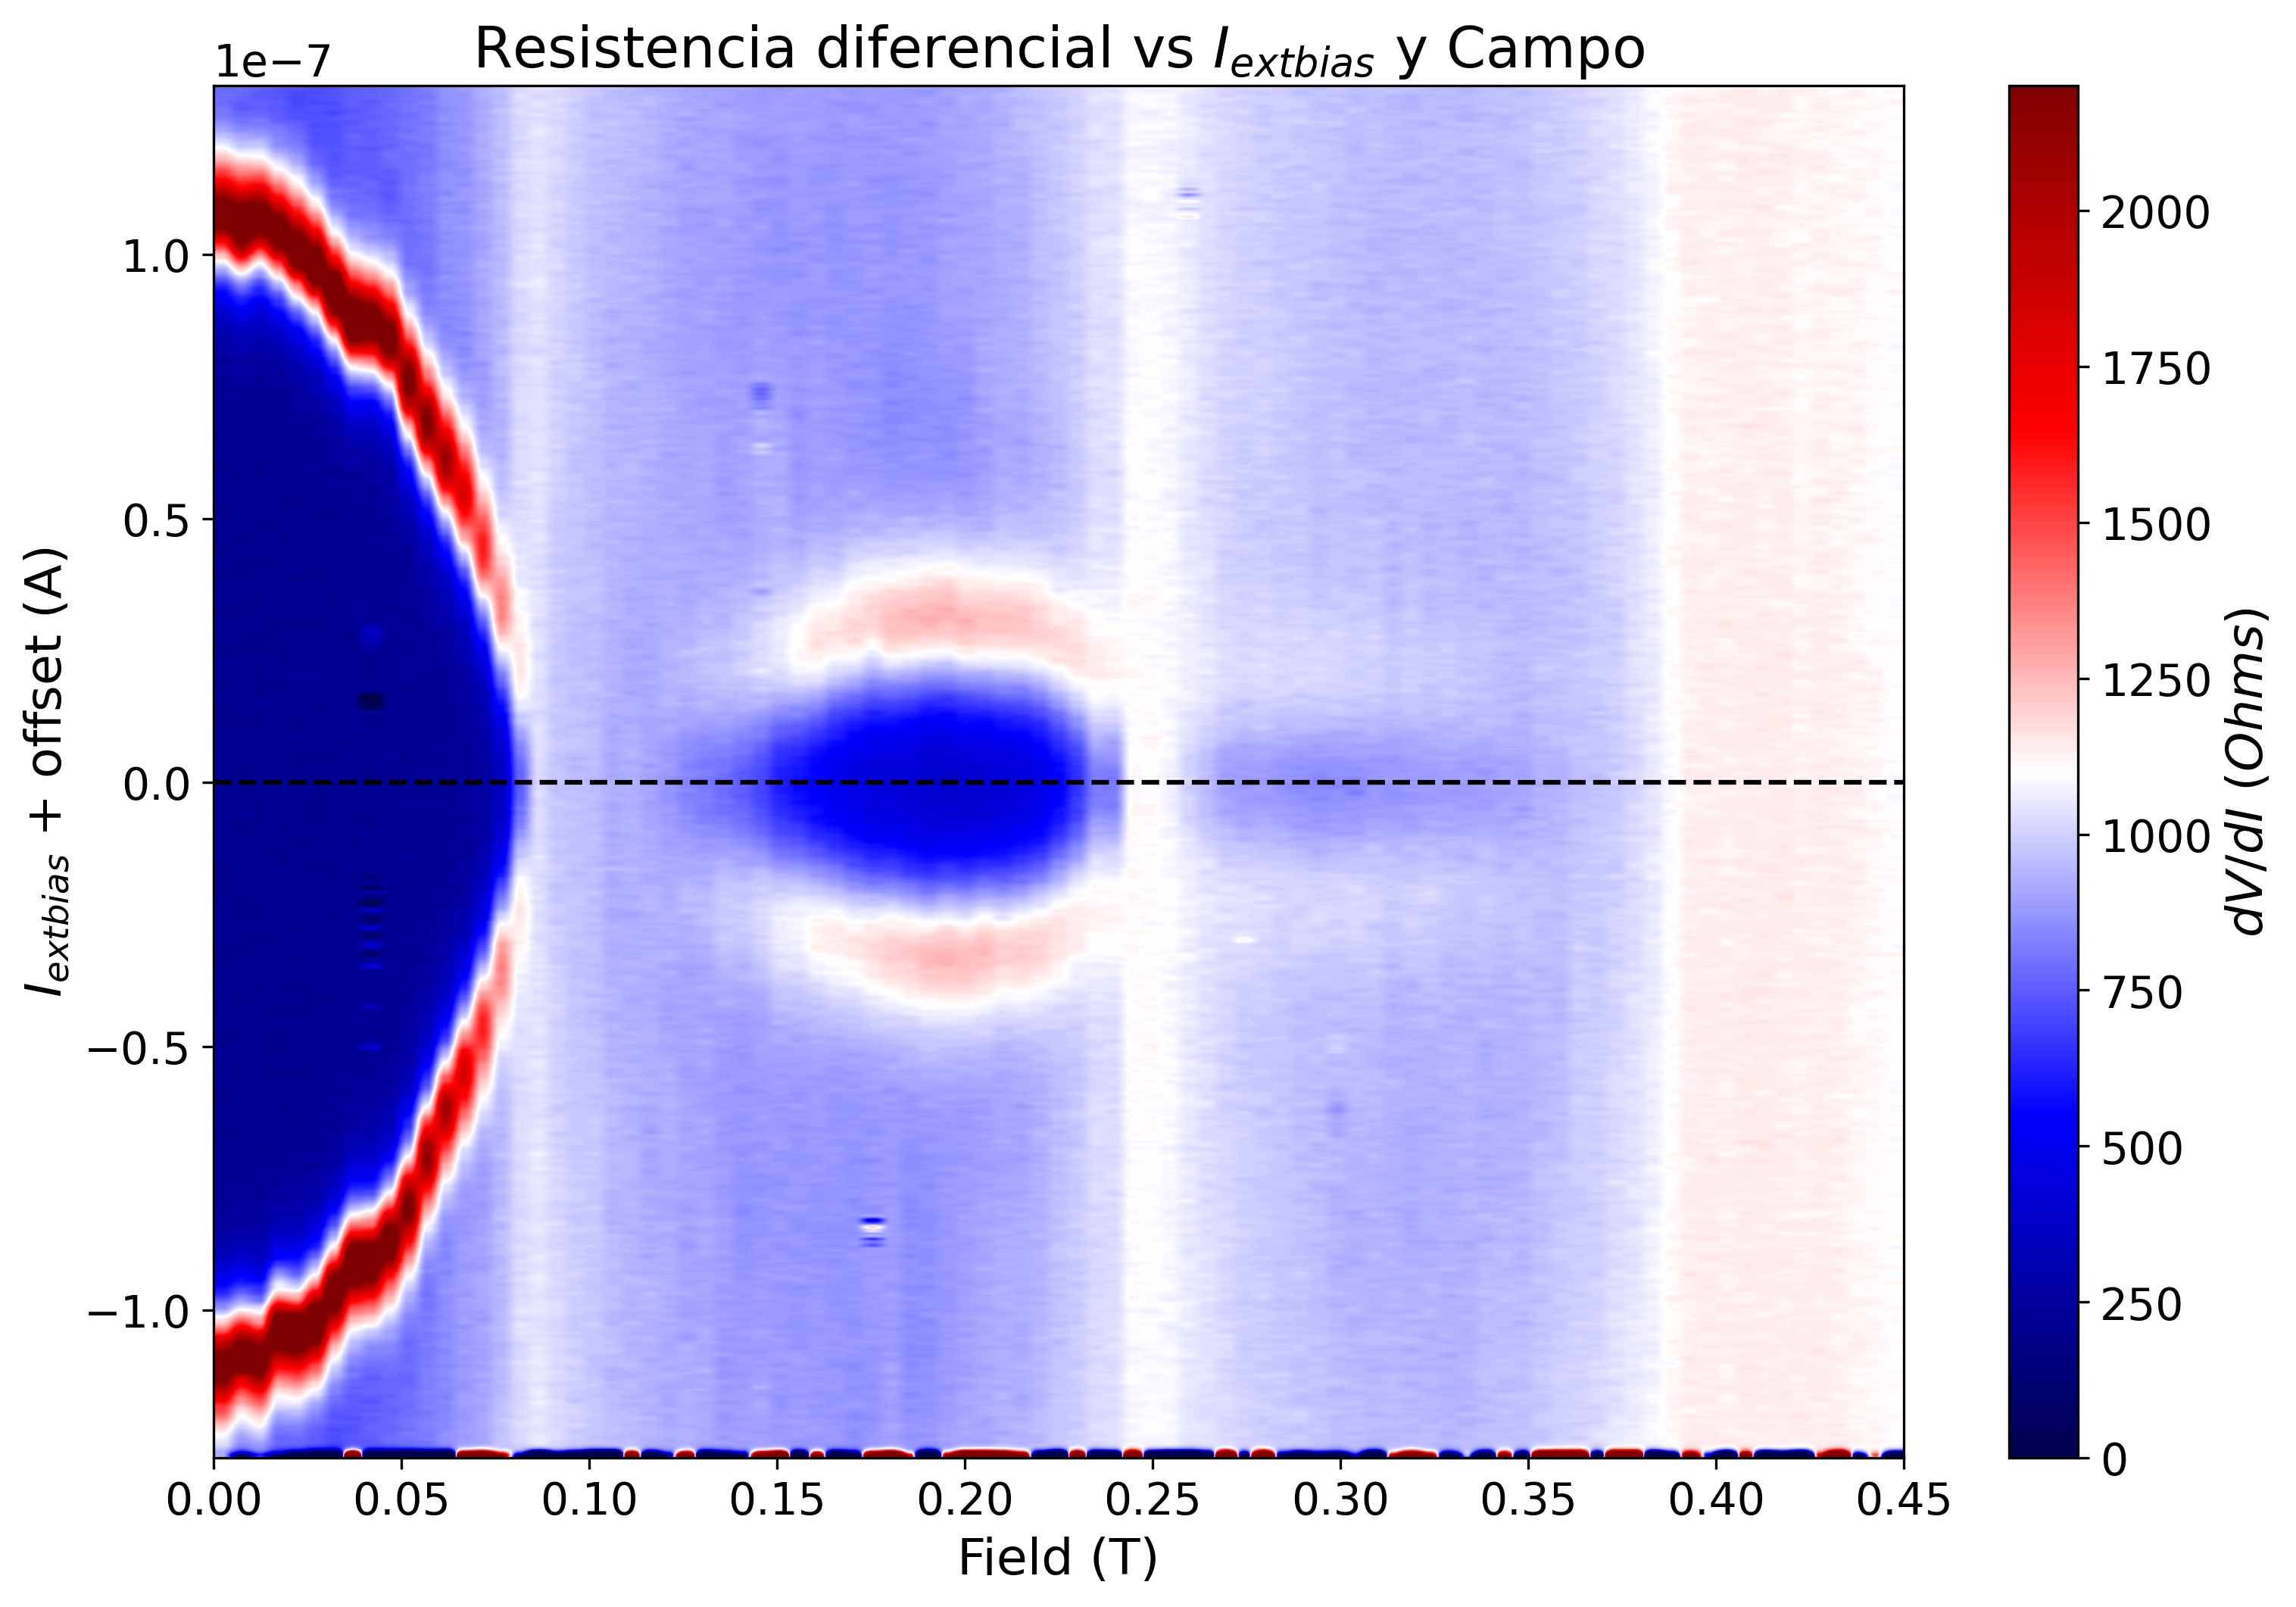

In [12]:
# Crear un mapa de color para dI/dV con offset
plt.imshow(dVdI_matrix, aspect='auto', origin='lower', 
           extent=[T_values.min(), T_values.max(), I_bias_withoffset.min(), I_bias_withoffset.max()], 
           cmap='seismic', vmin=0, vmax=2200)  # Ajusta vmin y vmax según tus datos
plt.colorbar(label='$dV/dI$ ($Ohms$)')
plt.xlabel('Field (T)')
plt.ylabel('$I_{\text{bias}}$ + offset (A)')
plt.axhline(0, color='black', linestyle='--')  # maya en y=0
plt.title('Resistencia diferencial vs $I_{\text{bias}}$ y Campo')
plt.show()

# Linecuts

In [13]:
def extract_vertical_linecut(data_matrix, x_value, x_axis, y_axis):
    """
    Extrae un corte vertical (linecut) de la matriz de datos en un valor específico de x.
    
    Parámetros:
    - data_matrix: Matriz 2D con los datos.
    - x_value: Valor en el eje x donde se extraerá el corte.
    - x_axis: Valores del eje x (temperatura).
    - y_axis: Valores del eje y (corriente).
    
    Retorna:
    - y_values: Valores del eje y.
    - data_line: Valores del corte vertical.
    """
    x_index = np.argmin(np.abs(x_axis - x_value))  # Encuentra el índice más cercano al valor de x
    y_values = y_axis
    data_line = data_matrix[:, x_index]
    return y_values, data_line

In [14]:
def extract_horizontal_linecut(data_matrix, y_value, x_axis, y_axis):
    """
    Extrae un corte horizontal (linecut) de la matriz de datos en un valor específico de y.
    
    Parámetros:
    - data_matrix: Matriz 2D con los datos.
    - y_value: Valor en el eje y donde se extraerá el corte.
    - x_axis: Valores del eje x (temperatura).
    - y_axis: Valores del eje y (corriente).
    
    Retorna:
    - x_values: Valores del eje x.
    - data_line: Valores del corte horizontal.
    """
    y_index = np.argmin(np.abs(y_axis - y_value))  # Encuentra el índice más cercano al valor de y
    x_values = x_axis
    data_line = data_matrix[y_index, :]
    return x_values, data_line

## 1) DC linecuts

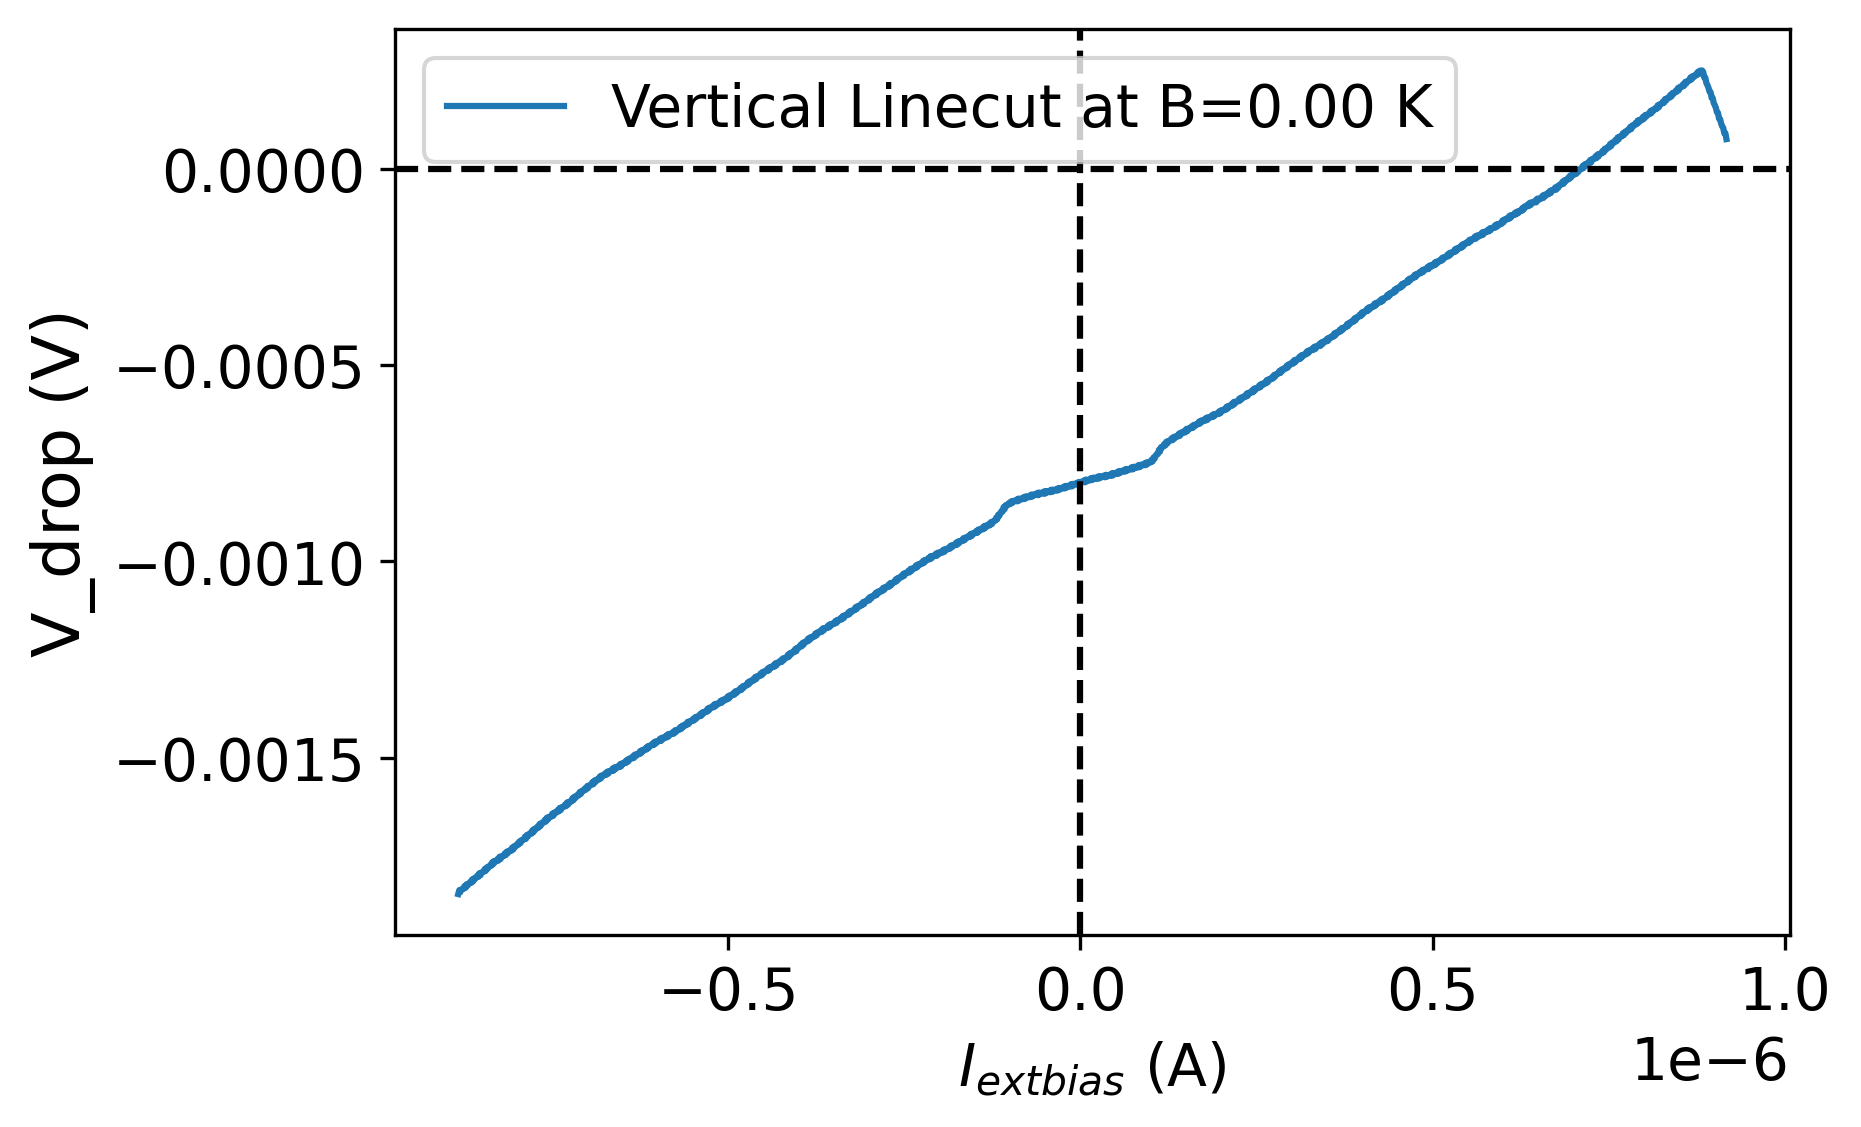

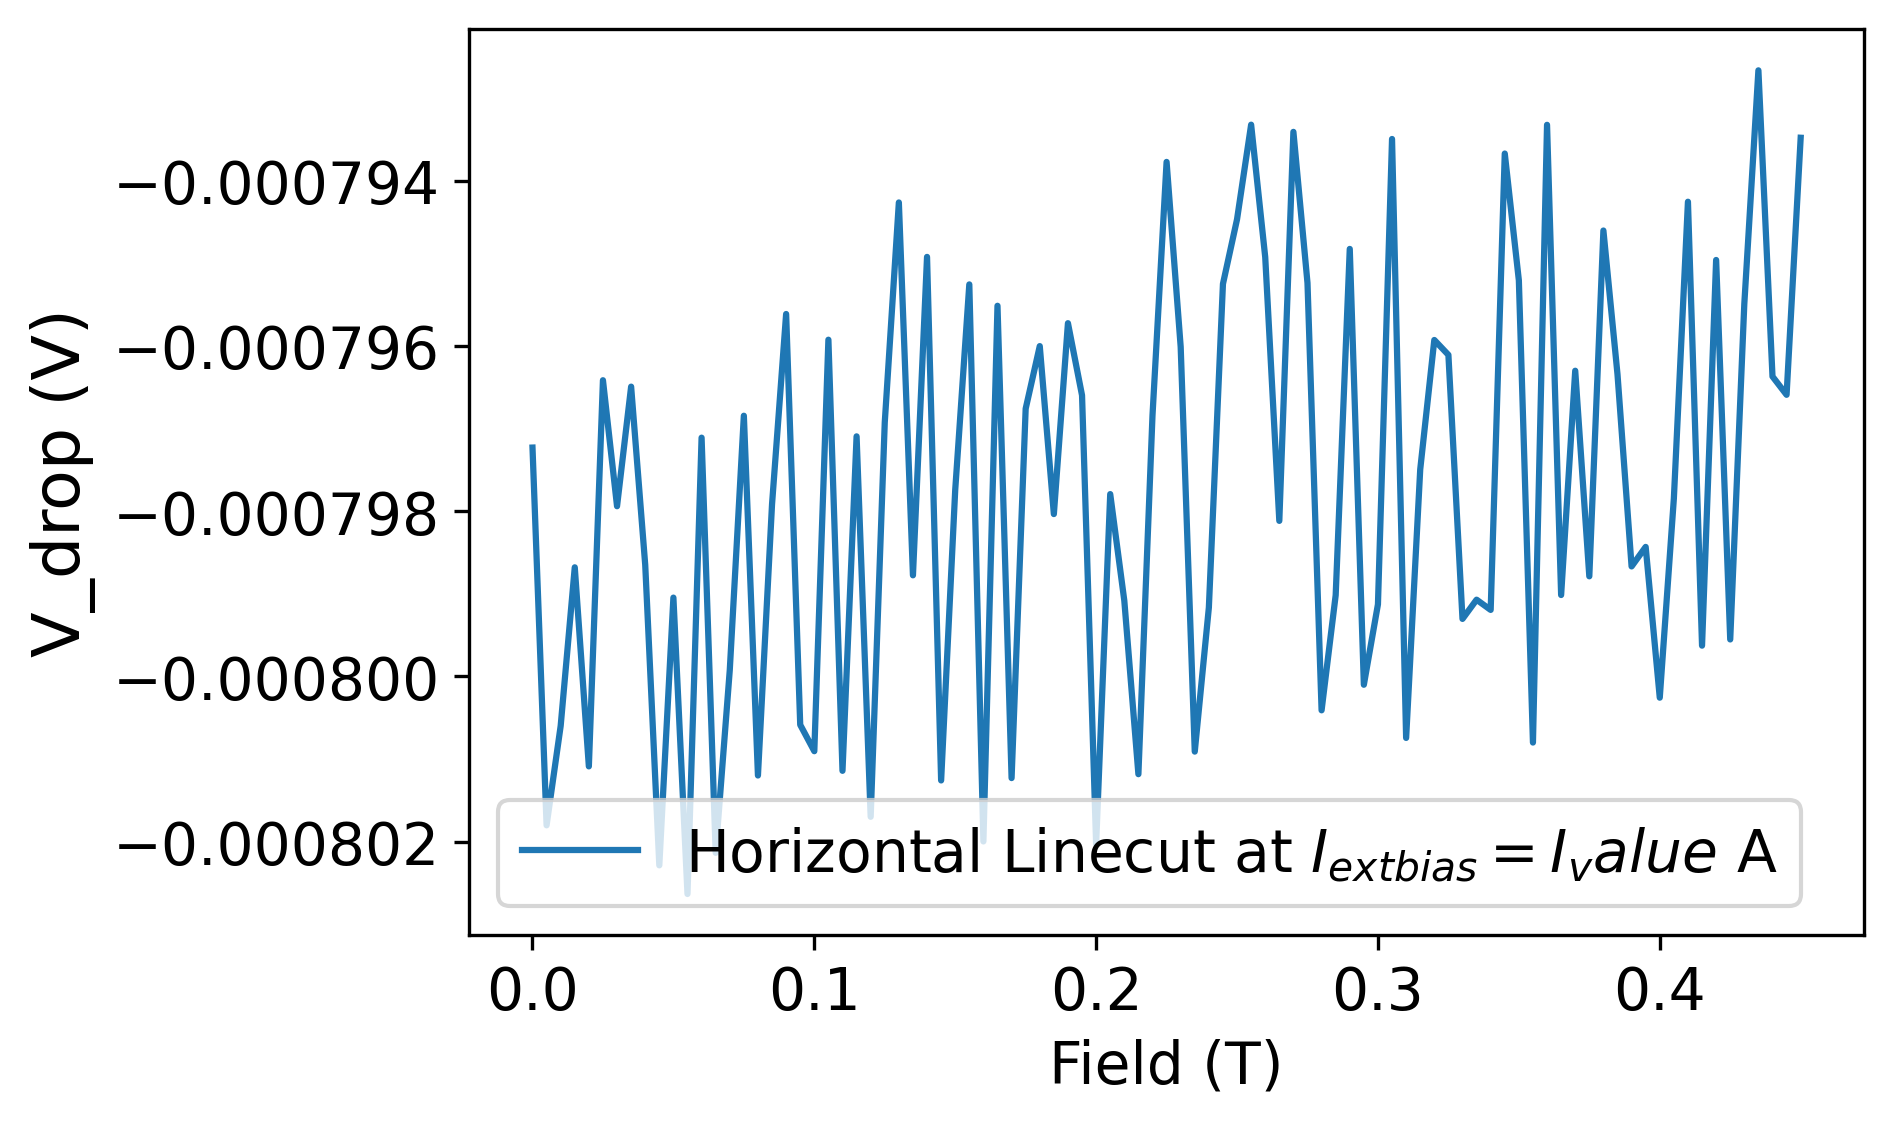

In [33]:
# Extraer un corte vertical en una temperatura específica (por ejemplo, la primera temperatura)
T_value = T_values[0]  # Primera temperatura en el vector
y_values, vertical_line = extract_vertical_linecut(V_real_matrix, T_value, T_values, I_bias_withoffset)

# Graficar el corte vertical
plt.figure(figsize=(6, 4))
plt.plot(y_values, vertical_line, label=f"Vertical Linecut at B={T_value:.2f} K")
plt.xlabel('$I_{\text{bias}}$ (A)', fontsize=14)
plt.ylabel('V_drop (V)')
plt.axhline(0, color='black', linestyle='--')  # maya en y=0
plt.axvline(0, color='black', linestyle='--')  # maya en x=0
plt.legend()
plt.show()


# Extraer un corte horizontal en una corriente específica (por ejemplo, I_bias = 0)
I_value = 0.0  # Corriente específica
x_values, horizontal_line = extract_horizontal_linecut(V_real_matrix, I_value, T_values, I_bias_withoffset)

# Graficar el corte horizontal
plt.figure(figsize=(6, 4))
plt.plot(x_values, horizontal_line, label="Horizontal Linecut at $I_{\text{bias}}={I_value}$ A")
plt.xlabel('Field (T)', fontsize=14)
plt.ylabel('V_drop (V)')
plt.legend()
plt.show()

### V_offset correction

In [34]:
Voffset=-0.8e-3 
V_real_matrix -= Voffset

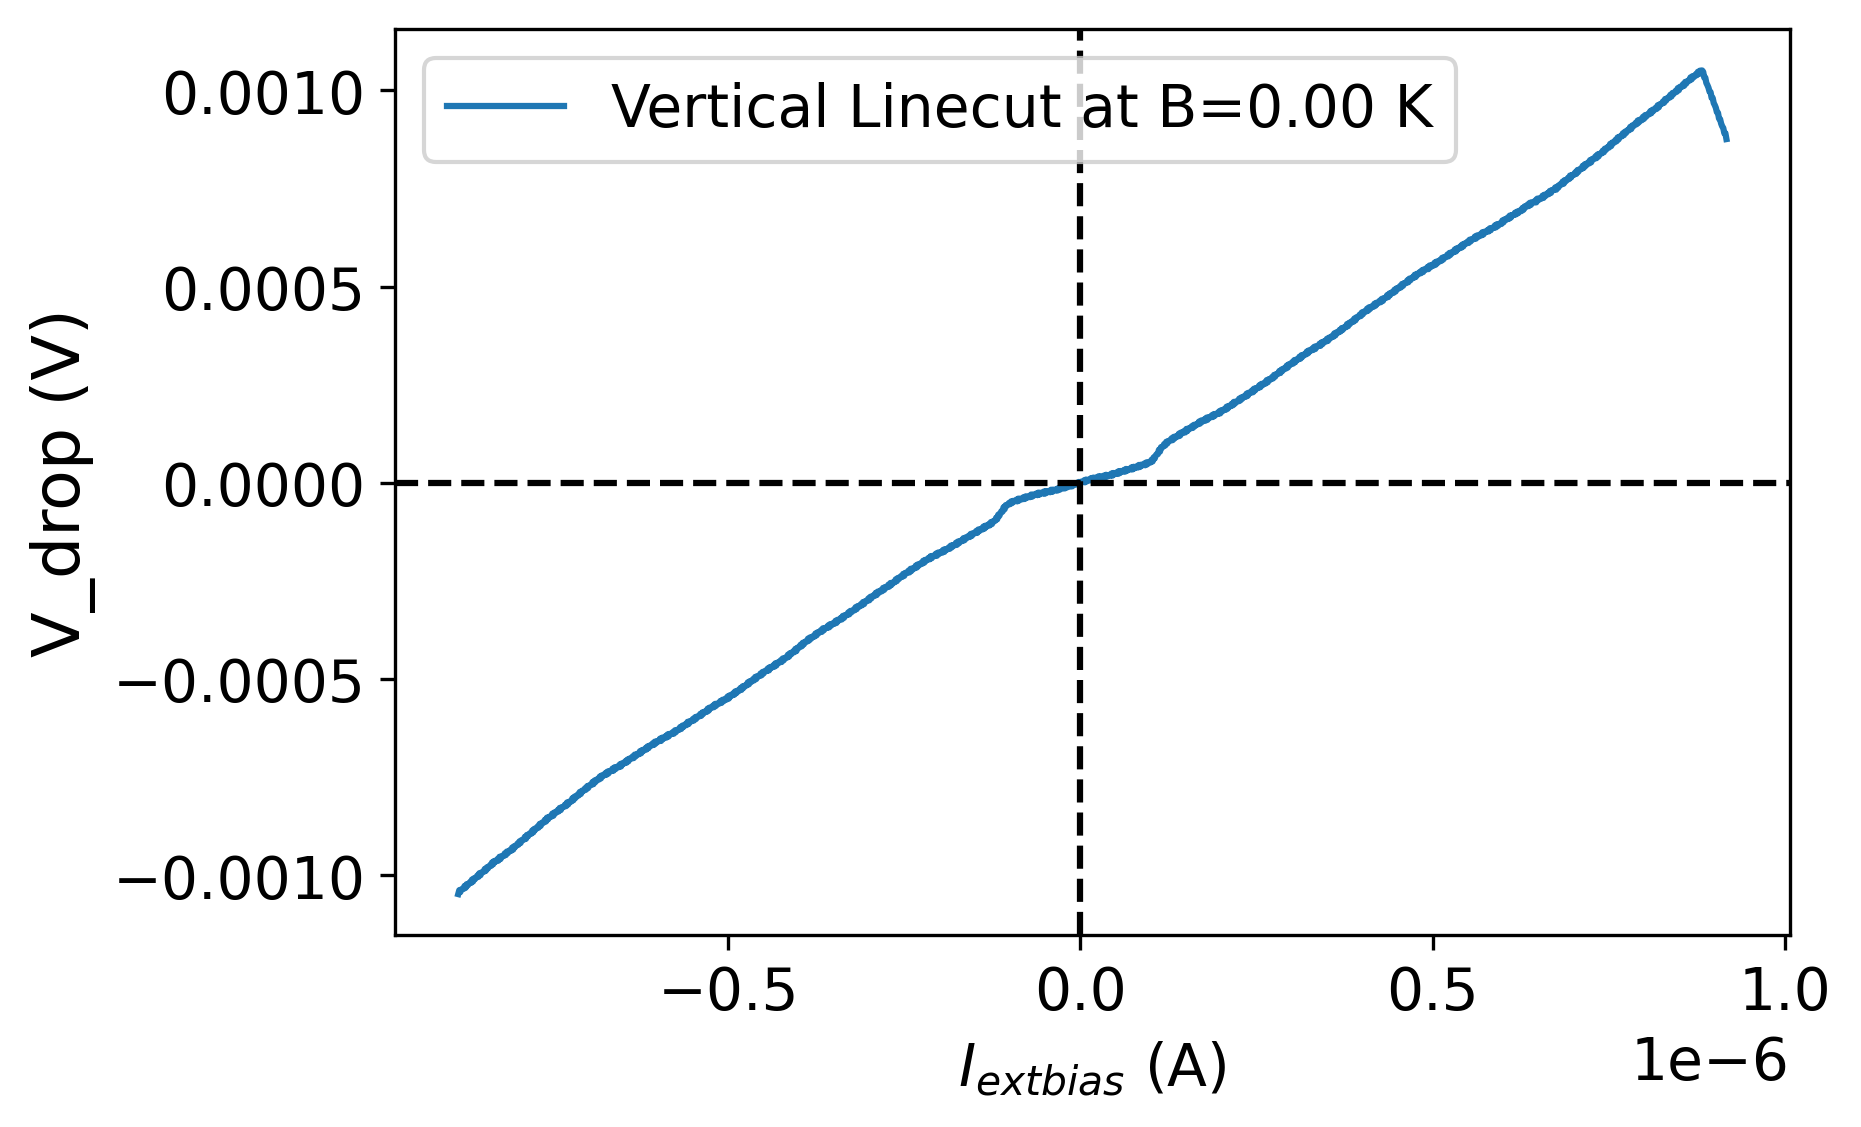

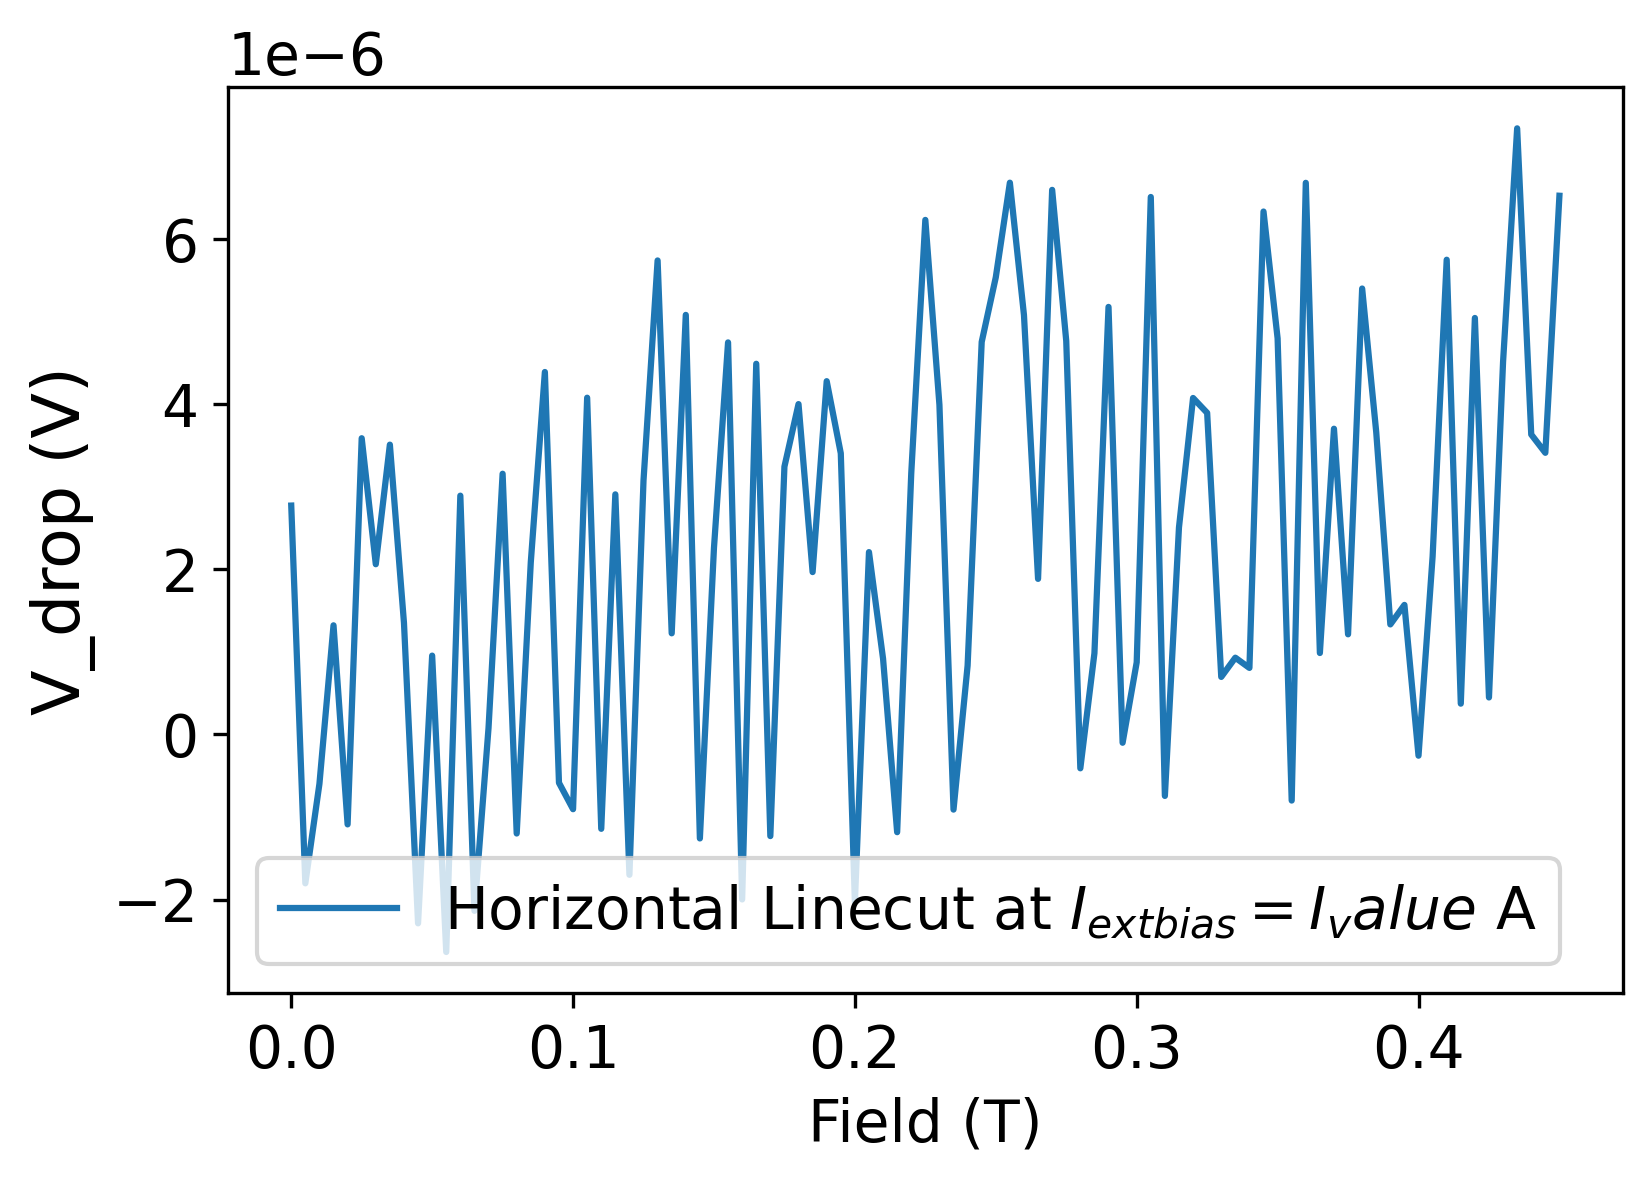

In [35]:
# Extraer un corte vertical en una temperatura específica (por ejemplo, la primera temperatura)
T_value = T_values[0]  # Primera temperatura en el vector
y_values, vertical_line = extract_vertical_linecut(V_real_matrix, T_value, T_values, I_bias_withoffset)

# Graficar el corte vertical
plt.figure(figsize=(6, 4))
plt.plot(y_values, vertical_line, label=f"Vertical Linecut at B={T_value:.2f} K")
plt.xlabel('$I_{\text{bias}}$ (A)', fontsize=14)
plt.ylabel('V_drop (V)')
plt.axhline(0, color='black', linestyle='--')  # maya en y=0
plt.axvline(0, color='black', linestyle='--')  # maya en x=0
plt.legend()
plt.show()


# Extraer un corte horizontal en una corriente específica (por ejemplo, I_bias = 0)
I_value = 0.0  # Corriente específica
x_values, horizontal_line = extract_horizontal_linecut(V_real_matrix, I_value, T_values, I_bias_withoffset)

# Graficar el corte horizontal
plt.figure(figsize=(6, 4))
plt.plot(x_values, horizontal_line, label="Horizontal Linecut at $I_{\text{bias}}={I_value}$ A")
plt.xlabel('Field (T)', fontsize=14)
plt.ylabel('V_drop (V)')
plt.legend()
plt.show()

## 2) AC linecuts

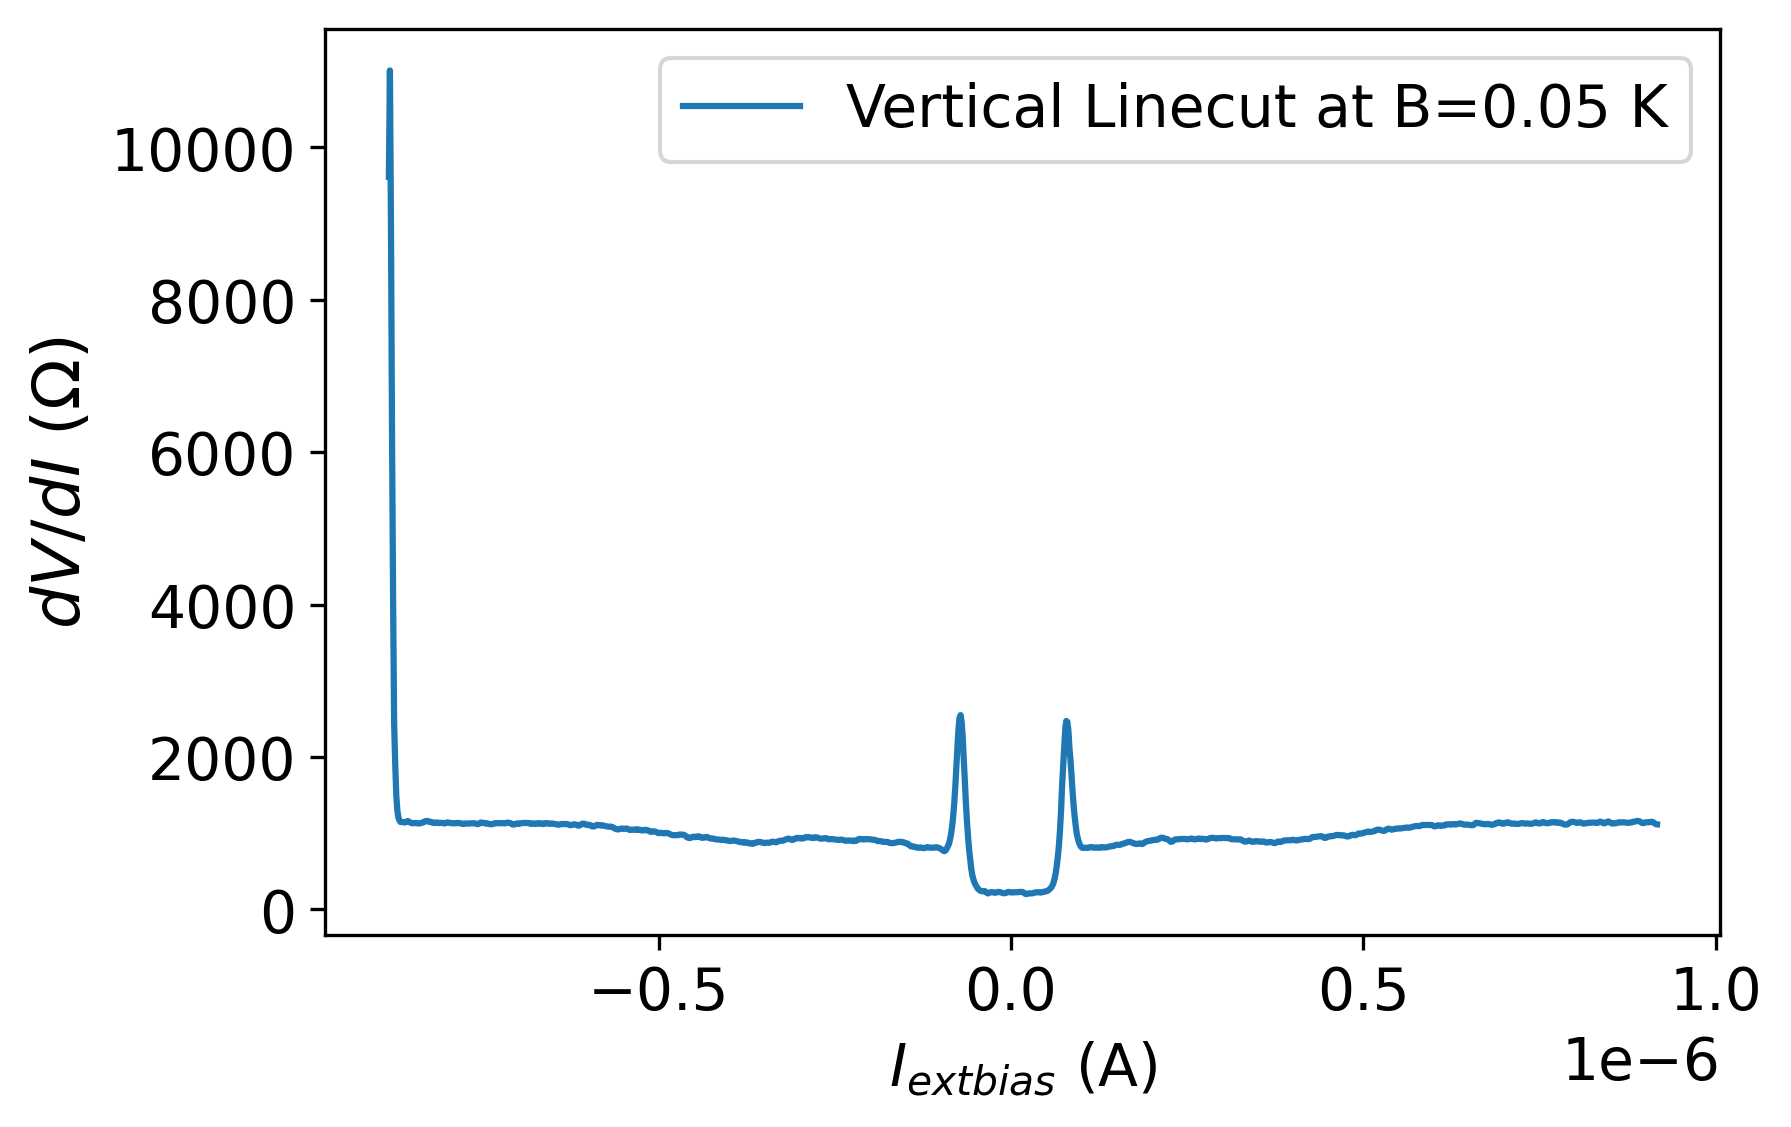

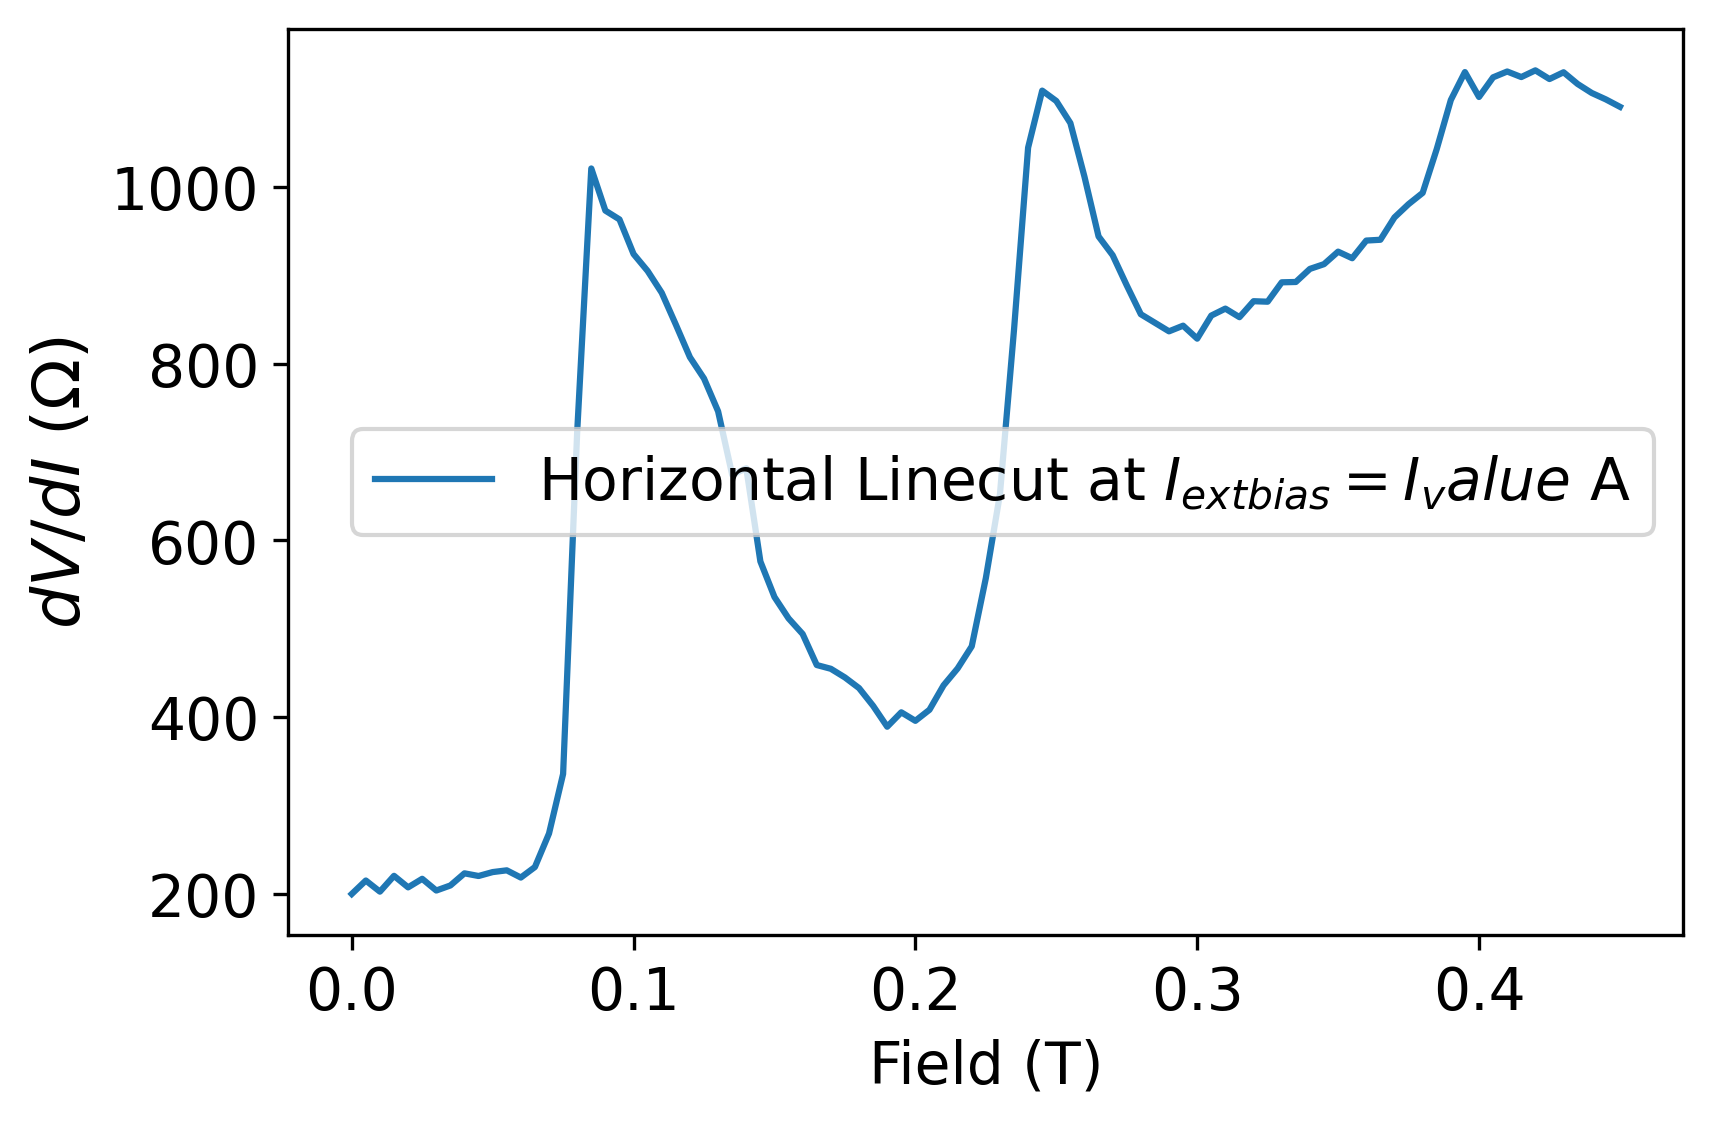

In [36]:
# Extraer un corte vertical en una temperatura específica (por ejemplo, la primera temperatura)
T_value = T_values[10]  # Primera temperatura en el vector
y_values, vertical_line = extract_vertical_linecut(dVdI_matrix, T_value, T_values, I_bias_withoffset)

# Graficar el corte vertical
plt.figure(figsize=(6, 4))
plt.plot(y_values, vertical_line, label=f"Vertical Linecut at B={T_value:.2f} K")
plt.xlabel('$I_{\text{bias}}$ (A)', fontsize=14)
plt.ylabel('$dV/dI$ ($\Omega$)')
plt.legend()
plt.show()


# Extraer un corte horizontal en una corriente específica (por ejemplo, I_bias = 0)
I_value = 0.0  # Corriente específica
x_values, horizontal_line = extract_horizontal_linecut(dVdI_matrix, I_value, T_values, I_bias_withoffset)

# Graficar el corte horizontal
plt.figure(figsize=(6, 4))
plt.plot(x_values, horizontal_line, label="Horizontal Linecut at $I_{\text{bias}}={I_value}$ A")
plt.xlabel('Field (T)', fontsize=14)
plt.ylabel('$dV/dI$ ($\Omega$)')
plt.legend()
plt.show()

# Rn

In [21]:
I_values

array([-3.90300000e-08, -3.88633352e-08, -3.86966705e-08, ...,
        1.60634382e-07,  1.60801046e-07,  1.60967711e-07])

In [22]:
I_bias_withoffset

array([-1.02030000e-07, -1.01863335e-07, -1.01696670e-07, ...,
        9.76343820e-08,  9.78010460e-08,  9.79677110e-08])

In [23]:
from scipy.stats import linregress

def calculate_normal_resistance(V_real_matrix, dVdI_matrix, T_values, I_bias_withoffset, I_1, I_2):
    """
    Calcula la resistencia normal usando la medida DC (regresión lineal) y la medida AC (promedio de dV/dI).

    Parámetros:
    - V_real_matrix: Matriz 2D con los datos de voltaje real (V_real).
    - dVdI_matrix: Matriz 2D con los datos de resistencia diferencial (dV/dI).
    - T_values: Valores de temperatura.
    - I_values: Valores de corriente.
    - I_1: Límite inferior de corriente para el cálculo.
    - I_2: Límite superior de corriente para el cálculo.

    Retorna:
    - R_normal_DC: Resistencia normal calculada con la medida DC (regresión lineal).
    - R_normal_AC: Resistencia normal calculada con la medida AC (promedio de dV/dI).
    """
    R_normal_DC = np.zeros(len(T_values))  # Para almacenar la resistencia normal (DC)
    R_normal_AC = np.zeros(len(T_values))  # Para almacenar la resistencia normal (AC)

    # Iterar sobre cada valor de temperatura
    for i, T in enumerate(T_values):
        # Obtener los datos de voltaje real y resistencia diferencial para esta temperatura
        V_real = V_real_matrix[:, i]
        dVdI = dVdI_matrix[:, i]
        
        # Filtrar los datos dentro del rango de corriente [I_1, I_2]
        I_mask = (I_bias_withoffset >= I_1) & (I_bias_withoffset <= I_2)
        I_region = I_bias_withoffset[I_mask]
        V_real_region = V_real[I_mask]
        dVdI_region = dVdI[I_mask]
        
        # Calcular la resistencia normal usando la medida DC (regresión lineal)
        if len(I_region) > 1:
            slope, _, _, _, _ = linregress(I_region, V_real_region)
            R_normal_DC[i] = slope  # La pendiente es la resistencia normal
        else:
            R_normal_DC[i] = np.nan  # Si no hay suficientes datos, asignar NaN
        
        # Calcular la resistencia normal usando la medida AC (promedio de dV/dI)
        R_normal_AC[i] = np.mean(dVdI_region)  # Promedio de la resistencia diferencial
    
    return R_normal_DC, R_normal_AC

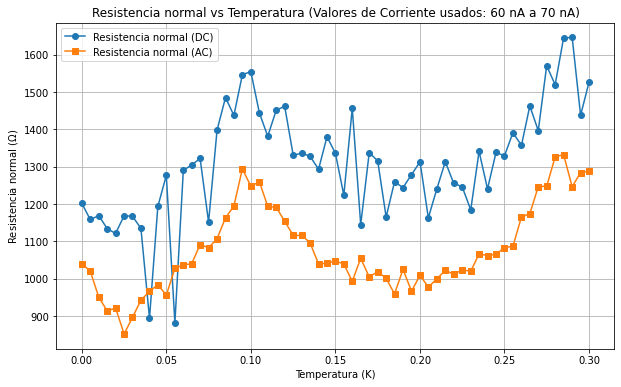

In [24]:
# Definir el rango de corriente para el cálculo de la resistencia normal
I_1 = 60e-9  # Límite inferior de corriente (200 nA)
I_2 = 70e-9  # Límite superior de corriente (300 nA)

# Calcular la resistencia normal usando ambas metodologías
R_normal_DC, R_normal_AC = calculate_normal_resistance(V_real_matrix, dVdI_matrix, T_values, I_bias_withoffset, I_1, I_2)

# Graficar las resistencias normales en función de la temperatura
plt.figure(figsize=(10, 6))
plt.plot(T_values, R_normal_DC, 'o-', label='Resistencia normal (DC)')
plt.plot(T_values, R_normal_AC, 's-', label='Resistencia normal (AC)')
plt.xlabel('Temperatura (K)')
plt.ylabel('Resistencia normal ($\Omega$)')
plt.title(f'Resistencia normal vs Temperatura (Valores de Corriente usados: {I_1*1e9:.0f} nA a {I_2*1e9:.0f} nA)')
plt.legend()
plt.grid(True)
plt.show()

# Find Peaks para I_c en un rango de B

In [15]:
import numpy as np

def filter_and_track_conductance_dip(dIdV_matrix, T_values, I_bias_withoffset,
                                     T_min, T_max,
                                     I_init, window_size):
    """
    Filtra el eje de temperaturas T_values en [T_min, T_max] y luego, para cada 
    temperatura filtrada, busca de forma iterativa el mínimo local (dip) de 
    conductancia diferencial, asumiendo que se desplaza poco respecto a la 
    temperatura anterior.
    
    Parámetros
    ----------
    dIdV_matrix : np.ndarray, shape (nI, nT)
        Matriz 2D de la conductancia diferencial. El eje 0 son los índices de
        I_bias_withoffset y el eje 1 son los índices de T_values.
    T_values : array-like, shape (nT,)
        Vector del eje lento (por ejemplo, temperaturas).
    I_bias_withoffset : array-like, shape (nI,)
        Vector del eje rápido (por ejemplo, bias de corriente).
    T_min, T_max : float
        Límites de temperatura para filtrar.
    I_init : float
        Estimación inicial de la corriente donde se ubica el dip en la primera T.
    window_size : int
        Semiancho de la ventana (en número de índices) para la búsqueda local 
        alrededor del dip anterior.

    Returns
    -------
    T_values_filtered : np.ndarray
        Vector de temperaturas solo en el rango [T_min, T_max].
    I_dips : np.ndarray, shape (nT_filtrado,)
        Corriente en la que se encuentra el dip para cada temperatura filtrada.
    dIdV_dips : np.ndarray, shape (nT_filtrado,)
        Valor de dI/dV en el dip correspondiente.
        
    Ejemplo de uso
    --------------
    >>> T_values_f, I_dips, dIdV_dips = filter_and_track_conductance_dip(
    ...     dIdV_matrix, T_values, I_bias_withoffset,
    ...     T_min=0.3, T_max=1.37,
    ...     I_init=120e-9, window_size=50
    ... )
    >>> # Luego T_values_f vs I_dips:
    >>> plt.plot(T_values_f, I_dips*1e9, 'o-')
    >>> plt.xlabel('T (K)')
    >>> plt.ylabel('I_dip (nA)')
    >>> plt.show()
    """
    
    # 1) Filtrado del rango de temperatura
    mask = (T_values >= T_min) & (T_values <= T_max)
    T_values_filtered = T_values[mask]
    dIdV_matrix_filtered = dIdV_matrix[:, mask]

    # Variables auxiliares
    nT_f = len(T_values_filtered)
    nI   = len(I_bias_withoffset)
    
    # Arrays para guardar los resultados
    I_dips   = np.zeros(nT_f)
    dIdV_dips = np.zeros(nT_f)
    
    # 2) Búsqueda del dip en el primer barrido (primera temperatura filtrada)
    #    Localizamos el índice de corriente más cercano a I_init
    idx_guess = np.argmin(np.abs(I_bias_withoffset - I_init))
    
    # Ajustamos la ventana de índices para no salir del array
    left  = max(idx_guess - window_size, 0)
    right = min(idx_guess + window_size, nI - 1)
    
    # Tomamos la curva dI/dV en la primera temperatura filtrada (col=0)
    dIdV_slice = dIdV_matrix_filtered[left:right+1, 0]
    local_idx_min = np.argmin(dIdV_slice)
    idx_min_global = left + local_idx_min
    
    # Guardamos
    I_dips[0]   = I_bias_withoffset[idx_min_global]
    dIdV_dips[0] = dIdV_matrix_filtered[idx_min_global, 0]
    
    # 3) Repetir la búsqueda para las siguientes temperaturas filtradas
    for iT in range(1, nT_f):
        center = idx_min_global
        left  = max(center - window_size, 0)
        right = min(center + window_size, nI - 1)
        
        dIdV_slice = dIdV_matrix_filtered[left:right+1, iT]
        local_idx_min = np.argmin(dIdV_slice)
        idx_min_global = left + local_idx_min
        
        I_dips[iT]   = I_bias_withoffset[idx_min_global]
        dIdV_dips[iT] = dIdV_matrix_filtered[idx_min_global, iT]
    
    return T_values_filtered, I_dips, dIdV_dips


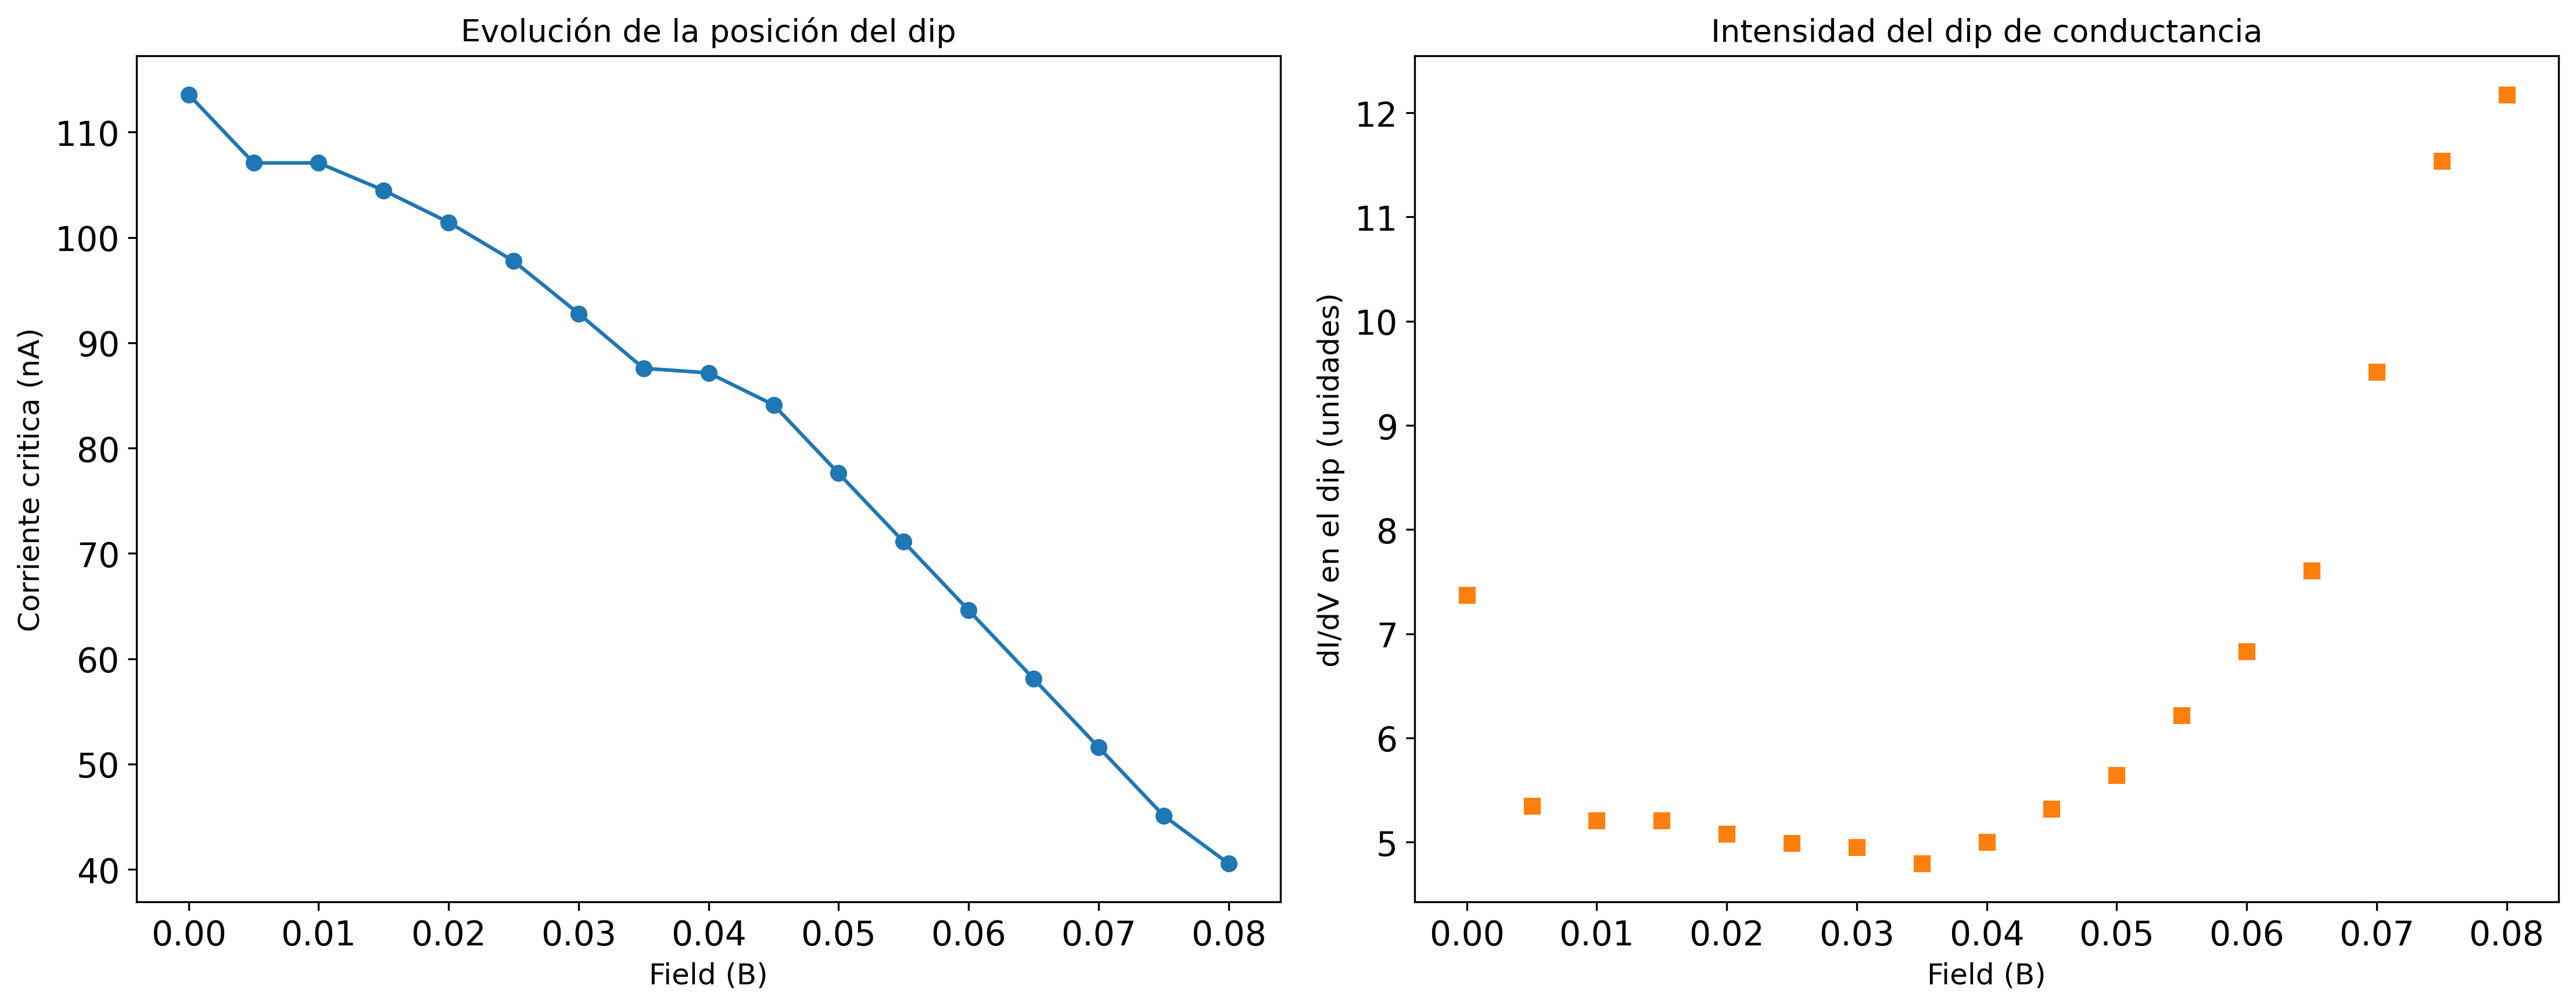

In [38]:
T_values_filtered, I_dips, dIdV_dips = filter_and_track_conductance_dip(
    dIdV_matrix=dIdV_matrix,
    T_values=T_values,
    I_bias_withoffset=I_bias_withoffset,
    T_min=0,
    T_max=0.08,
    I_init=120e-9,
    window_size=30
)

# 2) Gráficos para analizar la posición del dip y su valor

plt.figure(figsize=(15,6))

# (a) Posición del dip en corriente vs Temperatura
plt.subplot(1, 2, 1)
plt.plot(T_values_filtered, I_dips*1e9, 'o-', color='C0', markersize=6)
plt.xlabel('Field (B)', fontsize=12)
plt.ylabel('Corriente critica (nA)', fontsize=12)
plt.title('Evolución de la posición del dip', fontsize=13)
plt.grid(False)

# (b) Valor de dI/dV en el dip vs Temperatura
plt.subplot(1, 2, 2)
plt.plot(T_values_filtered, dIdV_dips, 's', color='C1')
plt.xlabel('Field (B)', fontsize=12)
plt.ylabel('dI/dV en el dip (unidades)', fontsize=12)
plt.title('Intensidad del dip de conductancia', fontsize=13)
plt.grid(False)

plt.tight_layout()
plt.show()

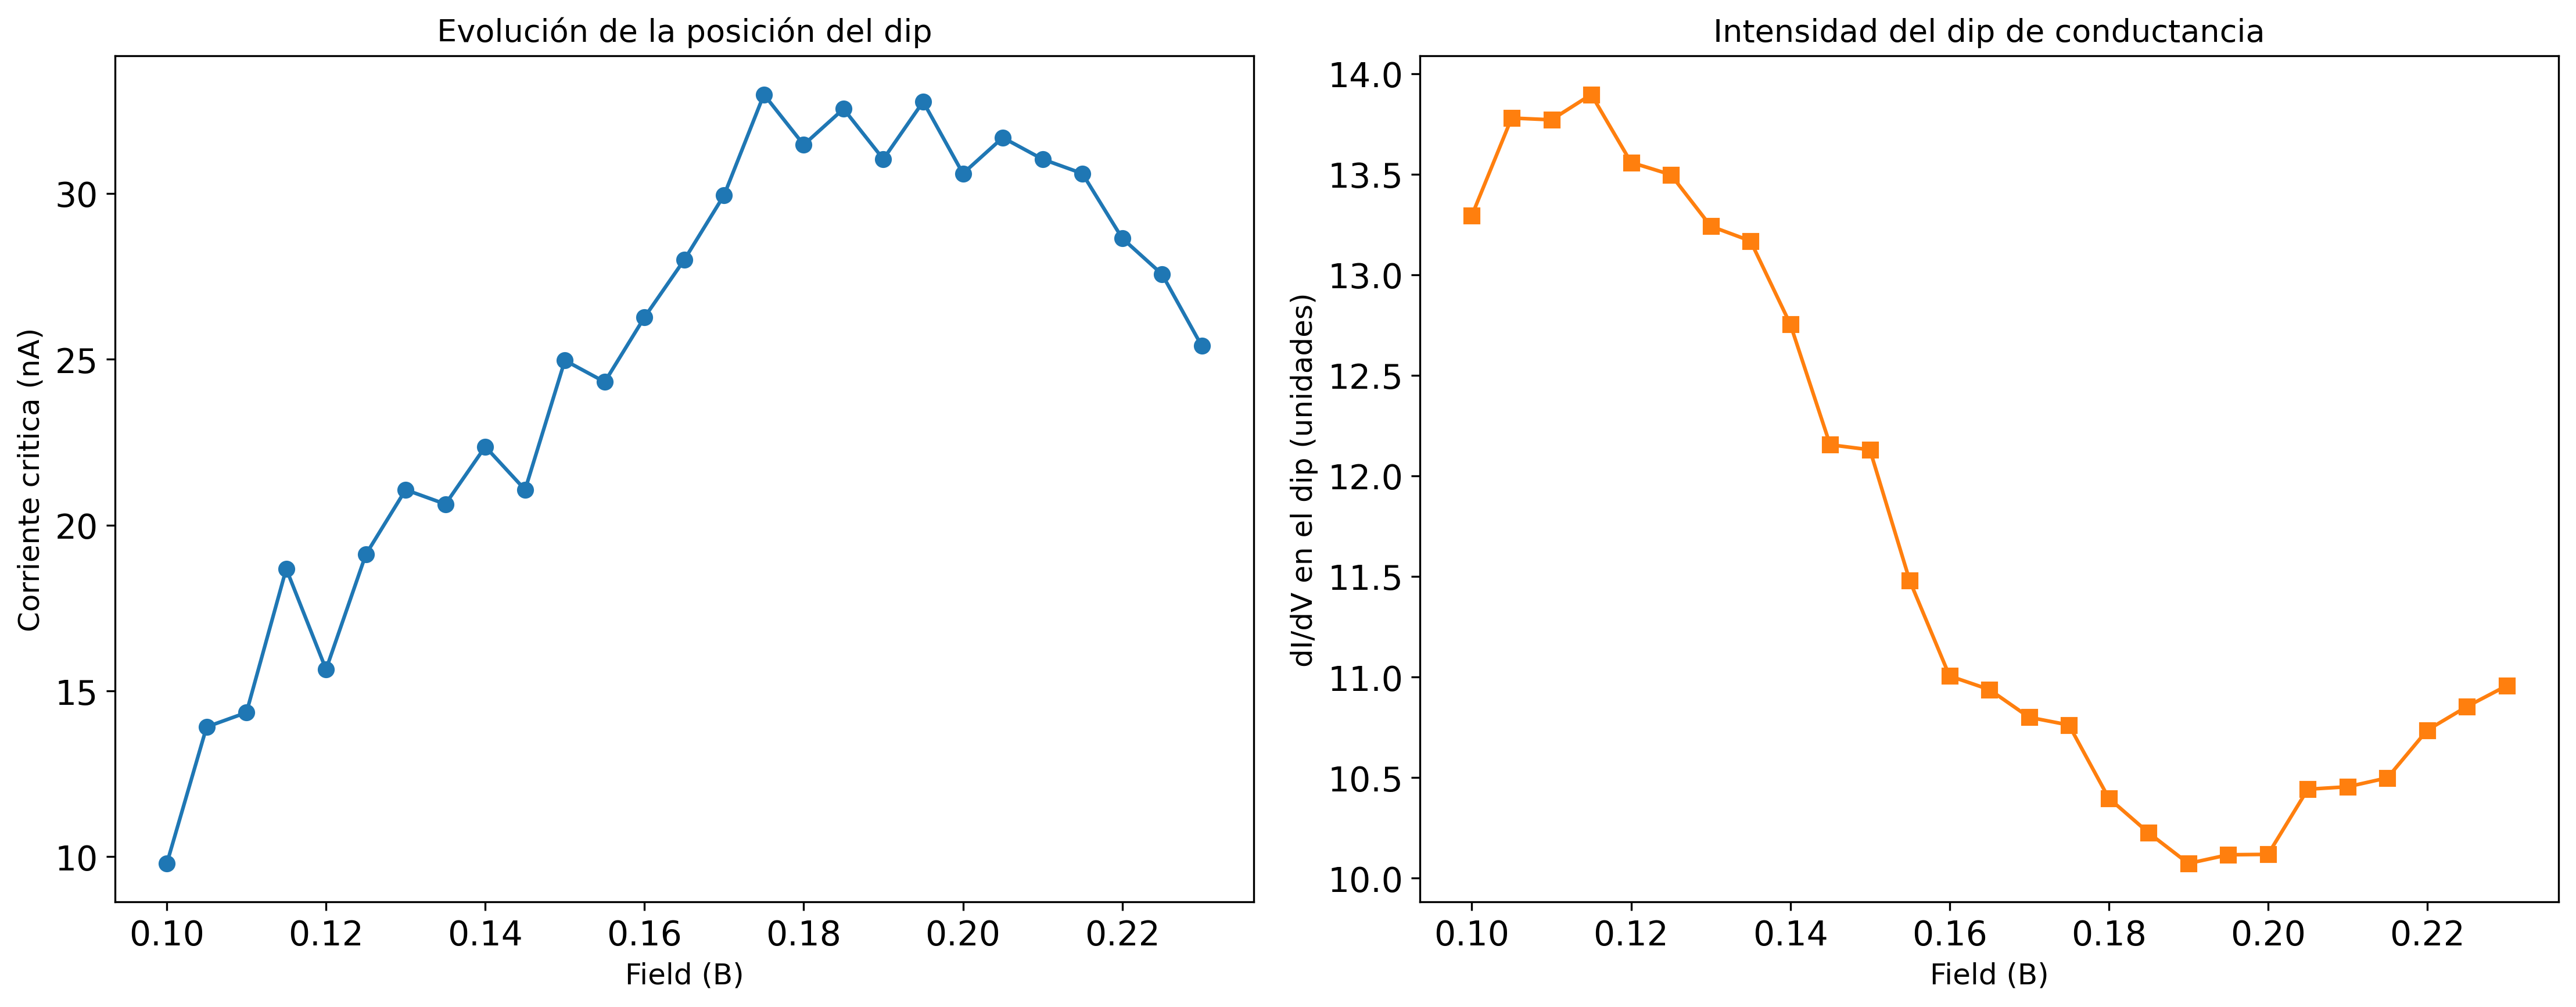

In [37]:
T_values_filtered, I_dips, dIdV_dips = filter_and_track_conductance_dip(
    dIdV_matrix=dIdV_matrix,
    T_values=T_values,
    I_bias_withoffset=I_bias_withoffset,
    T_min=0.10,
    T_max=0.23,
    I_init=10e-9,
    window_size=20
)

# 2) Gráficos para analizar la posición del dip y su valor

plt.figure(figsize=(15,6))

# (a) Posición del dip en corriente vs Temperatura
plt.subplot(1, 2, 1)
plt.plot(T_values_filtered, I_dips*1e9, 'o-', color='C0', markersize=6)
plt.xlabel('Field (B)', fontsize=12)
plt.ylabel('Corriente critica (nA)', fontsize=12)
plt.title('Evolución de la posición del dip', fontsize=13)
plt.grid(False)

# (b) Valor de dI/dV en el dip vs Temperatura
plt.subplot(1, 2, 2)
plt.plot(T_values_filtered, dIdV_dips, 's-', color='C1')
plt.xlabel('Field (B)', fontsize=12)
plt.ylabel('dI/dV en el dip (unidades)', fontsize=12)
plt.title('Intensidad del dip de conductancia', fontsize=13)
plt.grid(False)

plt.tight_layout()
plt.show()

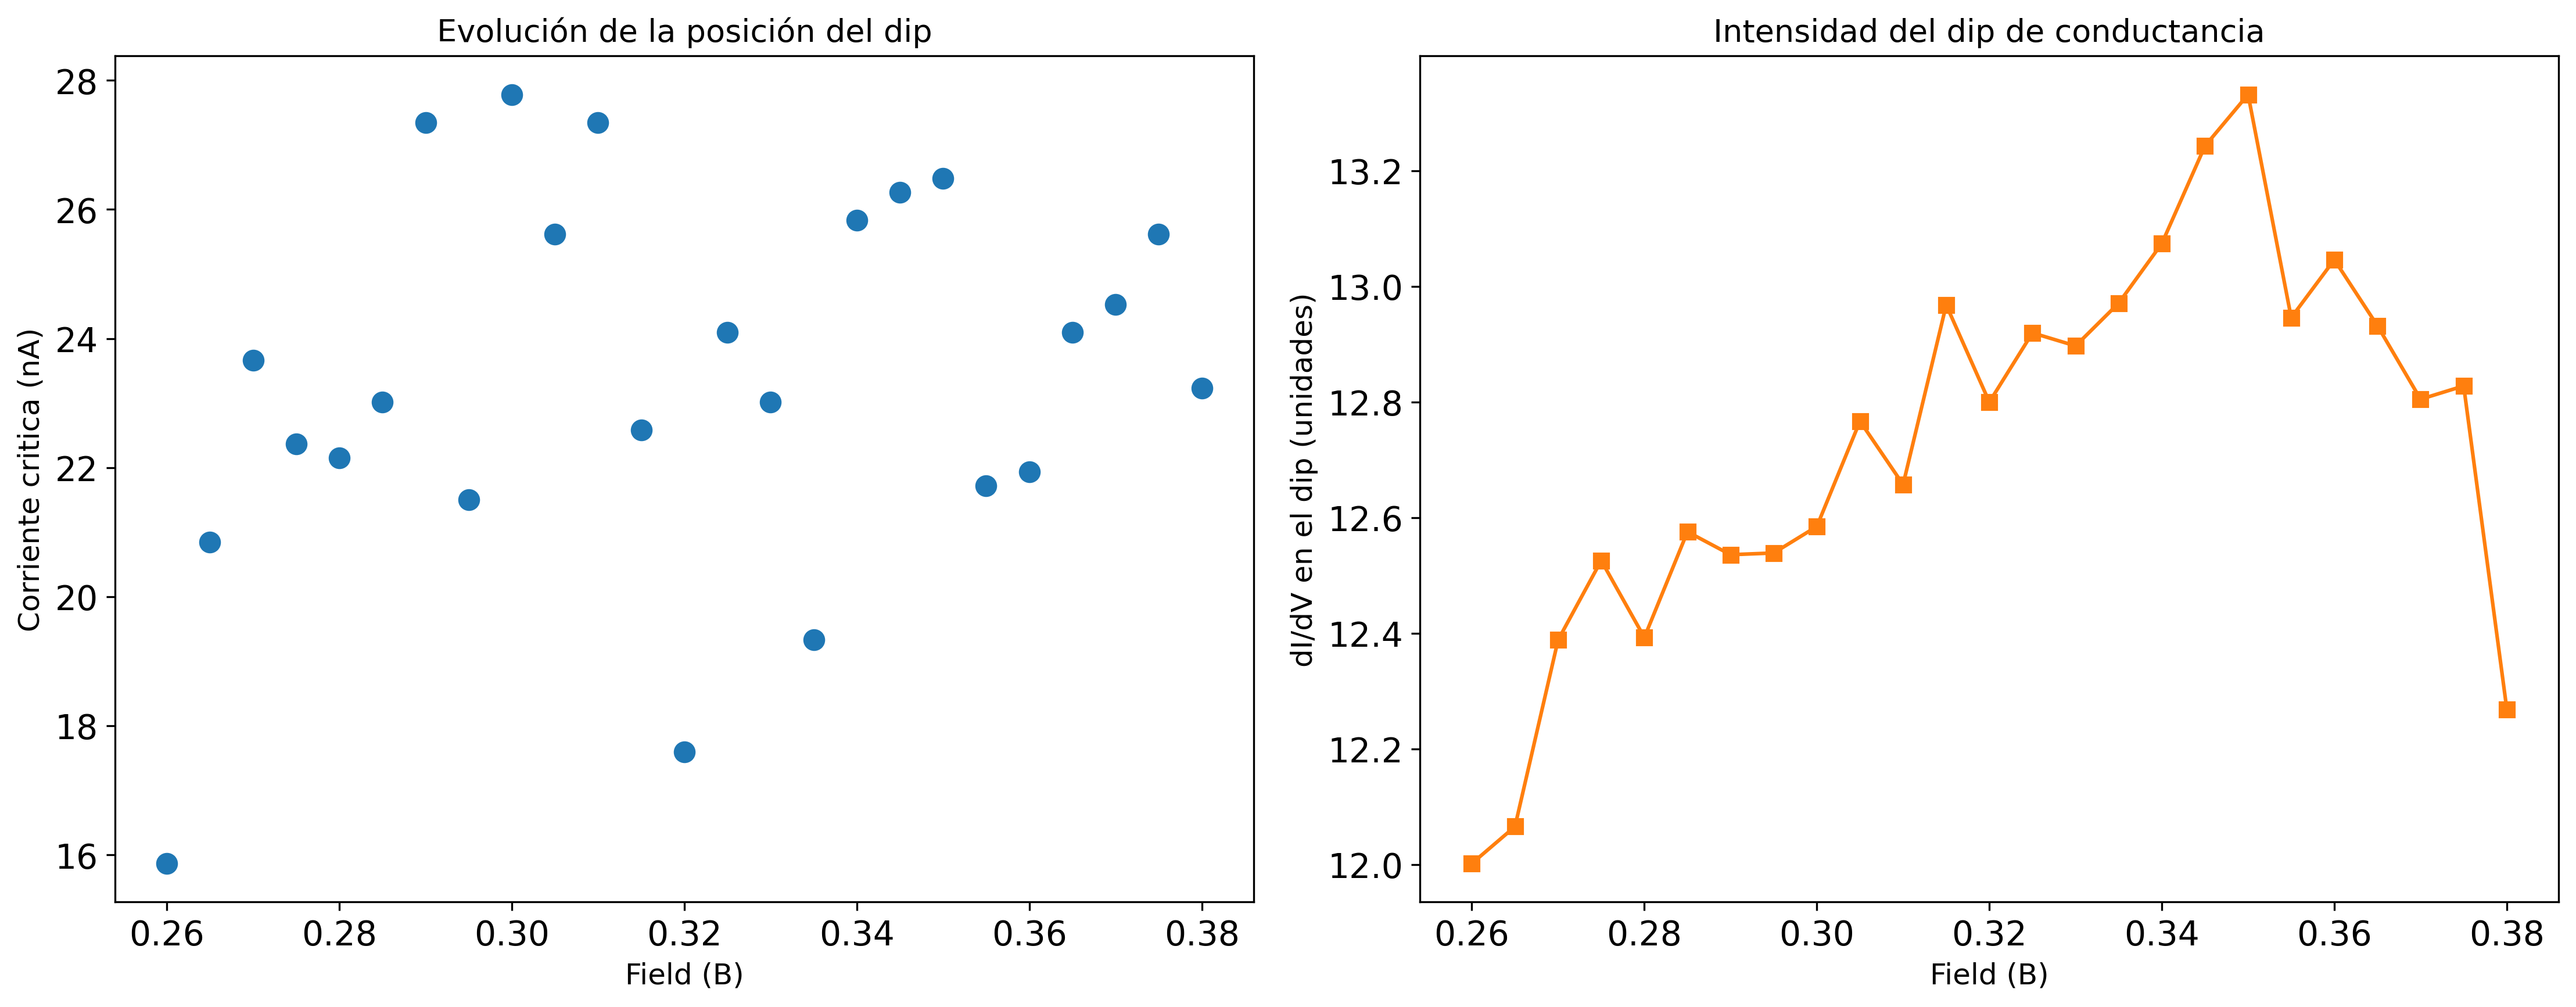

In [41]:
T_values_filtered, I_dips, dIdV_dips = filter_and_track_conductance_dip(
    dIdV_matrix=dIdV_matrix,
    T_values=T_values,
    I_bias_withoffset=I_bias_withoffset,
    T_min=0.26,
    T_max=0.38,
    I_init=10e-9,
    window_size=30
)

# 2) Gráficos para analizar la posición del dip y su valor

plt.figure(figsize=(15,6))

# (a) Posición del dip en corriente vs Temperatura
plt.subplot(1, 2, 1)
plt.plot(T_values_filtered, I_dips*1e9, 'o', color='C0', markersize=8)
plt.xlabel('Field (B)', fontsize=12)
plt.ylabel('Corriente critica (nA)', fontsize=12)
plt.title('Evolución de la posición del dip', fontsize=13)
plt.grid(False)

# (b) Valor de dI/dV en el dip vs Temperatura
plt.subplot(1, 2, 2)
plt.plot(T_values_filtered, dIdV_dips, 's-', color='C1')
plt.xlabel('Field (B)', fontsize=12)
plt.ylabel('dI/dV en el dip (unidades)', fontsize=12)
plt.title('Intensidad del dip de conductancia', fontsize=13)
plt.grid(False)

plt.tight_layout()
plt.show()

In [49]:
T_values_filtered

array([-0.04999223, -0.04496092, -0.04004609, -0.03498165, -0.03003802,
       -0.02504183, -0.01997031, -0.01496489, -0.00997577, -0.00503527,
        0.        ,  0.00504572,  0.01003549,  0.01502059,  0.019951  ,
        0.0250335 ,  0.02996426,  0.0350428 ,  0.03997724,  0.0450329 ,
        0.0500408 ,  0.05504742,  0.05996069,  0.06498257,  0.06999088,
        0.07495978,  0.08003547,  0.08496748,  0.09003971,  0.09499281,
        0.1000096 ,  0.10501574,  0.11000869,  0.11504336,  0.11998947,
        0.12497317,  0.13003631,  0.13503525,  0.14003123,  0.14498471,
        0.14995862,  0.15504358,  0.15997718,  0.16496345,  0.17004388,
        0.17502515,  0.1799705 ,  0.18502156,  0.19001921,  0.19496431,
        0.19997873,  0.2050042 ,  0.20997908,  0.215007  ,  0.21998272,
        0.224953  ,  0.22999568,  0.23498205,  0.24004313,  0.24502005,
        0.25002263,  0.25497485,  0.25999754,  0.26503996,  0.27003587,
        0.27497567,  0.27998241,  0.28496467,  0.29004059,  0.29

In [40]:
I_dips

array([ 4.32403157e-08,  4.57402871e-08,  4.69902728e-08,  4.94902440e-08,
        5.07402300e-08,  5.19902160e-08,  5.32402010e-08,  5.44901870e-08,
        5.57401730e-08,  5.69901580e-08,  5.57401730e-08,  5.57401730e-08,
        5.57401730e-08,  5.44901870e-08,  5.32402010e-08,  5.19902160e-08,
        5.07402300e-08,  4.94902440e-08,  4.82402590e-08,  4.57402871e-08,
        4.44903014e-08,  4.19903300e-08,  3.94903587e-08,  3.69903873e-08,
        3.44904159e-08,  3.19904445e-08,  2.82404874e-08,  2.44905303e-08,
        1.94905875e-08,  2.07405732e-08,  1.57406304e-08,  1.44906447e-08,
       -1.42590262e-08, -1.42590262e-08, -1.55090119e-08,  1.57406304e-08,
        1.57406304e-08,  1.82406018e-08,  1.82406018e-08,  1.82406018e-08,
        1.82406018e-08,  1.82406018e-08,  1.82406018e-08,  1.94905875e-08,
        1.82406018e-08, -1.92589690e-08, -1.92589690e-08, -1.92589690e-08,
       -2.05089547e-08, -2.05089547e-08, -2.05089547e-08, -2.05089547e-08,
       -1.92589690e-08, -

# IcRn 

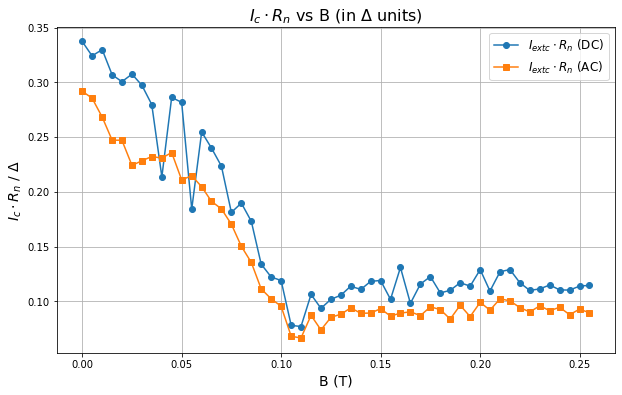

In [31]:
# CALCULO USANDO LA Ic (Idip) OBTENIDA A PARTIR DE LOS DIPS

# Recortar R_normal_DC y R_normal_AC para que tengan la misma longitud que T_values_filtered
R_normal_DC_filtered = R_normal_DC[:len(T_values_filtered)]
R_normal_AC_filtered = R_normal_AC[:len(T_values_filtered)]

# Calcular I_c * R_n con los vectores recortados
Ic_Rn_DC = I_dips * R_normal_DC_filtered  # Usando R_n de la medida DC
Ic_Rn_AC = I_dips * R_normal_AC_filtered  # Usando R_n de la medida AC

# Graficar I_exc * R_n en función de la temperatura
Delta=200e-6
plt.figure(figsize=(10, 6))
plt.plot(T_values_filtered, Ic_Rn_DC/Delta, 'o-', label='$I_{\text{c}} \cdot R_n$ (DC)')
plt.plot(T_values_filtered, Ic_Rn_AC/Delta, 's-', label='$I_{\text{c}} \cdot R_n$ (AC)')

plt.xlabel('B (T)', fontsize=14)  # Aumentar el tamaño de la etiqueta del eje x
plt.ylabel('$I_{c} \\cdot R_n$ / $\\Delta$', fontsize=14)  # Aumentar el tamaño de la etiqueta del eje y
plt.title("$I_{c} \\cdot R_n$ vs B (in $\\Delta$ units)", fontsize=16)  # Usar Delta (Δ) en el título
plt.legend(fontsize=12)  # Aumentar el tamaño de la leyenda si es necesario

plt.grid(True)

plt.show()

# Interpolacion en V

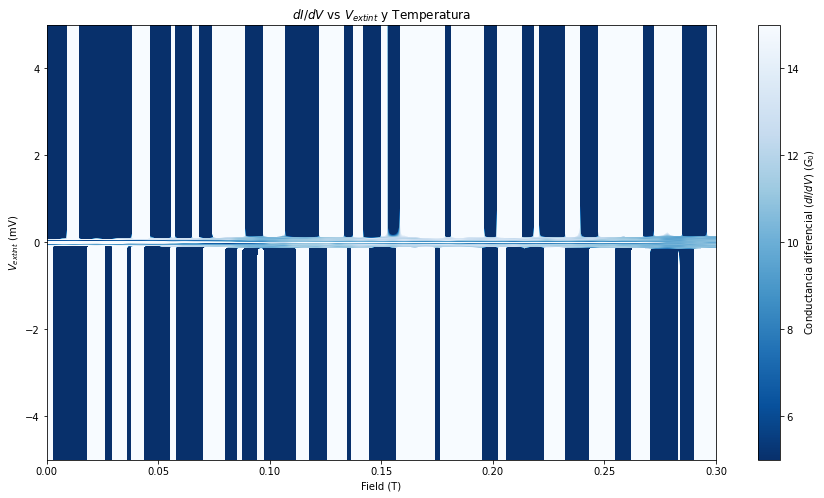

In [30]:
# Crear el nuevo eje de voltaje (V_int)
V_int = np.linspace(-0.005, 0.005, num=len(I_values))  # Misma resolución que el eje de corriente

# Crear matrices vacías para almacenar los datos interpolados
I_real_interp = np.zeros((len(V_int), len(T_values)))  # Para la medida DC (corriente)
dIdV_interp = np.zeros((len(V_int), len(T_values)))    # Para la medida AC (dI/dV)

# Interpolar los datos para cada temperatura
for i, T in enumerate(T_values):
    # Obtener los datos de voltaje, corriente y dI/dV para esta temperatura
    V_real = V_real_matrix[:, i]
    I_real = I_values  # Corriente
    dIdV = dIdV_matrix[:, i]  # Conductancia diferencial
    
    # Crear funciones de interpolación
    interp_I_real = interp1d(V_real, I_real, kind='linear', fill_value="extrapolate")
    interp_dIdV = interp1d(V_real, dIdV, kind='linear', fill_value="extrapolate")
    
    # Interpolar los datos en el nuevo eje de voltaje (V_int)
    I_real_interp[:, i] = interp_I_real(V_int)
    dIdV_interp[:, i] = interp_dIdV(V_int)

# Graficar la medida AC (dI/dV) en función de V_int y Temperatura
plt.figure(figsize=(15, 8))
plt.imshow(dIdV_interp, aspect='auto', origin='lower', 
           extent=[T_values.min(), T_values.max(), V_int.min() * 1e3, V_int.max() * 1e3], 
           cmap='Blues_r', vmin=5, vmax=15)
plt.colorbar(label='Conductancia diferencial ($dI/dV$) ($G_0$)')
plt.xlabel('Field (T)')
plt.ylabel('$V_{\text{int}}$ (mV)')
plt.title('$dI/dV$ vs $V_{\text{int}}$ y Temperatura')


plt.show()